# Pronóstico del consumo eléctrico de Tetuán a una hora

**TB1 · Metodología para Data Science (1ACC0240) · UPC · ciclo 2026-2 · Grupo 3**

Notebook 01 de CRISP-DM: comprensión de los datos y preparación. La comprensión del negocio está en
[`docs/negocio.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/negocio.md).

### Cambios respecto al avance (semana 7)

- La comprensión del negocio pasa a [`docs/negocio.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/negocio.md) y plantea el problema por
  subestación. Se pronostican las tres zonas con el mismo pipeline: la Zona 1 es el caso principal, la
  Zona 3 la prueba de estrés y la Zona 2 el contraste.
- El criterio de éxito se mide contra la mejor de tres referencias ingenuas (persistencia, ayer y semana
  pasada), no solo contra la persistencia.
- Los datos se leen del medallón (bronze → silver → gold), que guarda su procedencia y pasa una
  auditoría de calidad.
- La comprensión de los datos suma la firma de carga de cada zona, el efecto del clima, los días
  especiales (Ramadán y feriados) y una anomalía en la velocidad del viento.

# Configuración

En Colab se instala el código del repo y se monta Google Drive, donde viven las capas del medallón. En
local se usan las capas de `data/`.

In [1]:
import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    RAMA = "develop"  # rama del repo desde la que se instala el código
    !pip install -q "git+https://github.com/R0SEWT/tetouan-power-forecast@{RAMA}"

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from tetouan_power_forecast import HORIZONTE, metricas, perfiles
from tetouan_power_forecast.datos import PERIODOS_DIA, ZONAS
from tetouan_power_forecast.medallon import bronze, cargar_silver, silver, usar_drive

if EN_COLAB:
    usar_drive()  # Mi unidad/datalake/tetouan-power-forecast
else:
    os.environ.setdefault("TETOUAN_DATA", str(Path.cwd().parent / "data"))  # el notebook corre desde notebooks/

ZONES = ZONAS  # columnas de consumo de las tres zonas
COLORES = dict(zip(perfiles.NOMBRES, ["royalblue", "darkorange", "seagreen"]))

# Comprensión del Negocio

El detalle está en [`docs/negocio.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/negocio.md) y la evidencia, en
[`docs/investigacion.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/investigacion.md). En resumen:

- **Decisión:** el centro de control de Amendis decide cada 10 minutos si transferir carga o preparar una
  maniobra en una subestación antes de un pico. Para eso necesita el consumo de cada zona con **una hora
  de anticipación** (t+6).
- **Objetivo de data science:** un modelo de regresión por zona que estime el consumo en t+6 con la
  información disponible en t.
- **Papel de cada zona:** la Zona 1 es el caso principal (45 % de la demanda), la Zona 3 la prueba de
  estrés (costera, con picos de verano) y la Zona 2 el contraste (ritmo laboral).
- **Criterio de éxito:** ganarle a la mejor de tres referencias ingenuas (persistencia, ayer y semana
  pasada a la misma hora), también en las horas pico (19-22 h), y reportar cuántos picos se subestiman.

Esta sección contrasta las hipótesis H1 a H5 de la comprensión del negocio.

# Comprensión de los Datos

1. Fuente y procedencia
2. Estructura del archivo original y auditoría de calidad
3. Estadísticas descriptivas y una anomalía en el viento
4. Valores atípicos
5. Comportamiento temporal de los picos (H1)
6. Las tres zonas: firma de carga (H2)
7. Clima y consumo (H3)
8. Días especiales: Ramadán y feriados (H4)
9. Qué tan predecible es cada zona (H5)
10. Hallazgos

## Fuente y procedencia

Los datos vienen del dataset *Power Consumption of Tetouan City* del repositorio UCI (ID 849), y se leen
del medallón del proyecto. El **bronze** es el CSV tal como lo sirve UCI, sin tocar. Junto a él se guarda
su procedencia, incluido el sha256, que permite comprobar que nadie modificó el archivo.

In [3]:
procedencia = json.loads(bronze().with_suffix(".json").read_text())
campos = ["dataset", "pagina", "doi", "licencia", "origen", "descargado_utc", "bytes", "sha256"]
display(pd.DataFrame({"Valor": [procedencia[c] for c in campos]}, index=campos))

,Valor
dataset,Power Consumption of Tetouan City
pagina,https://archive.ics.uci.edu/dataset/849/power+...
doi,10.24432/C5B034
licencia,CC BY 4.0
origen,"SCADA de Amendis, operador de distribución elé..."
descargado_utc,2026-10-23T01:57:46+00:00
bytes,4222390
sha256,ca8b2f30cf07dd872cb7f2aa45dac110ee38dbe5fc5910...


| Variable | Descripción | Unidad |
|---|---|---|
| DateTime | Inicio del periodo de 10 minutos | — |
| Temperature | Temperatura de la ciudad | °C |
| Humidity | Humedad relativa | % |
| Wind Speed | Velocidad del viento | Sin unidad en la fuente |
| general diffuse flows | Radiación solar difusa general | Sin unidad en la fuente |
| diffuse flows | Radiación solar difusa | Sin unidad en la fuente |
| Zone 1, 2 y 3 Power Consumption | Consumo de cada zona | kW, según fuentes secundarias |

UCI no nombra las zonas ni da unidades. Las fuentes secundarias dicen que la red se alimenta de tres
subestaciones (Quads, Smir y Boussafou), pero ninguna dice qué zona es cada una. Por eso aquí se las
identifica por su comportamiento.

## Estructura del archivo original y auditoría de calidad

Así llega el CSV de UCI:

In [4]:
crudo = pd.read_csv(bronze())
print(f"Registros: {len(crudo):,} · Columnas: {crudo.shape[1]}")
print("\nTipos tal como llegan:")
print(crudo.dtypes.to_string())
print("\nColumnas con espacios dobles en el nombre:", [c for c in crudo.columns if "  " in c])
display(crudo.head(3))

Registros: 52,416 · Columnas: 9

Tipos tal como llegan:
DateTime                         str
Temperature                  float64
Humidity                     float64
Wind Speed                   float64
general diffuse flows        float64
diffuse flows                float64
Zone 1 Power Consumption     float64
Zone 2  Power Consumption    float64
Zone 3  Power Consumption    float64

Columnas con espacios dobles en el nombre: ['Zone 2  Power Consumption', 'Zone 3  Power Consumption']


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373


Hay dos problemas de formato. DateTime llega como texto (con el formato `m/d/aaaa h:mm`) y dos columnas
tienen espacios dobles en el nombre, lo que provoca errores al referenciarlas.

El **silver** los corrige: normaliza los nombres, convierte DateTime a fecha y ordena en el tiempo. Antes
de guardarse pasa una auditoría que detiene el pipeline si falla algún chequeo:

In [5]:
df = cargar_silver()
display(Markdown(silver().with_name("auditoria.md").read_text()))

# Auditoría del silver

Registros: 52,416 · desde 2017-01-01 00:00:00 hasta 2017-12-30 23:50:00

| Chequeo | Resultado | Detalle |
|---|---|---|
| Columnas esperadas | ok | 9 columnas |
| Sin valores faltantes | ok | 0 nulos |
| Sin filas duplicadas | ok | 0 duplicadas |
| Sin fechas repetidas | ok | 0 repetidas |
| Un registro cada 10 minutos, sin huecos | ok | 0 intervalos distintos de 10 min |
| Temperature entre -10 y 50 | ok | 0 fuera de rango |
| Humidity entre 0 y 100 | ok | 0 fuera de rango |
| Wind Speed >= 0 | ok | 0 fuera de rango |
| general diffuse flows >= 0 | ok | 0 fuera de rango |
| diffuse flows >= 0 | ok | 0 fuera de rango |
| Zone 1 Power Consumption > 0 | ok | 0 fuera de rango |
| Zone 2 Power Consumption > 0 | ok | 0 fuera de rango |
| Zone 3 Power Consumption > 0 | ok | 0 fuera de rango |


In [6]:
dias = df["DateTime"].dt.normalize()
faltantes = pd.date_range("2017-01-01", "2017-12-31").difference(dias.unique())
print(f"Del {df['DateTime'].min():%d/%m/%Y %H:%M} al {df['DateTime'].max():%d/%m/%Y %H:%M}: "
      f"{dias.nunique()} días × {PERIODOS_DIA} periodos = {len(df):,} registros")
print("Días de 2017 sin datos:", [f"{d:%d/%m}" for d in faltantes])

Del 01/01/2017 00:00 al 30/12/2017 23:50: 364 días × 144 periodos = 52,416 registros
Días de 2017 sin datos: ['31/12']


Los datos están completos dentro del periodo. No hay nulos, filas duplicadas ni fechas repetidas, y hay
un registro cada 10 minutos sin huecos. Los valores están dentro de rangos físicos posibles. Solo falta el
31 de diciembre. No hace falta imputar ni eliminar registros.

## Estadísticas descriptivas

In [7]:
numericas = df.drop(columns="DateTime")
resumen = numericas.describe().T
resumen["asimetría"] = numericas.skew()
resumen["CV (std / media)"] = resumen["std"] / resumen["mean"]
display(resumen.round(2))

,count,mean,std,min,25%,50%,75%,max,asimetría,CV (std / media)
Temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01,0.20,0.31
Humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80,-0.63,0.23
Wind Speed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48,0.46,1.20
general diffuse flows,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00,1.31,1.45
diffuse flows,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00,2.46,1.66
Zone 1 Power Consumption,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40,0.23,0.22
Zone 2 Power Consumption,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86,0.33,0.25
Zone 3 Power Consumption,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33,1.02,0.37


- **Consumo:** la Zona 1 es la de mayor nivel (unos 32,300 kW de media), seguida por la Zona 2 (21,000) y la
  Zona 3 (17,800). La Zona 3 tiene la mayor variación relativa (CV de 0.37) y es la única con asimetría
  marcada a la derecha (1.02), por sus picos de verano. En las Zonas 1 y 2, la media y la mediana casi
  coinciden.
- **Radiación difusa:** la mediana es casi 0, porque de noche no hay radiación, y tiene una cola larga
  hacia los valores del mediodía (asimetrías de 1.31 y 2.46). Sigue el ciclo día y noche.
- **Temperatura y humedad:** rangos plausibles para Tetuán (de 3 a 40 °C y de 11 a 95 %).
- **Velocidad del viento:** la mediana es 0.09, pero el percentil 75 salta a 4.92. Eso merece una mirada
  aparte.

### Una anomalía: la velocidad del viento tiene dos estados

Registros con viento < 1: 61.2% · entre 1 y 4: 0.18% · > 4: 38.6%
Veces que cambia de un estado al otro en el año: 130


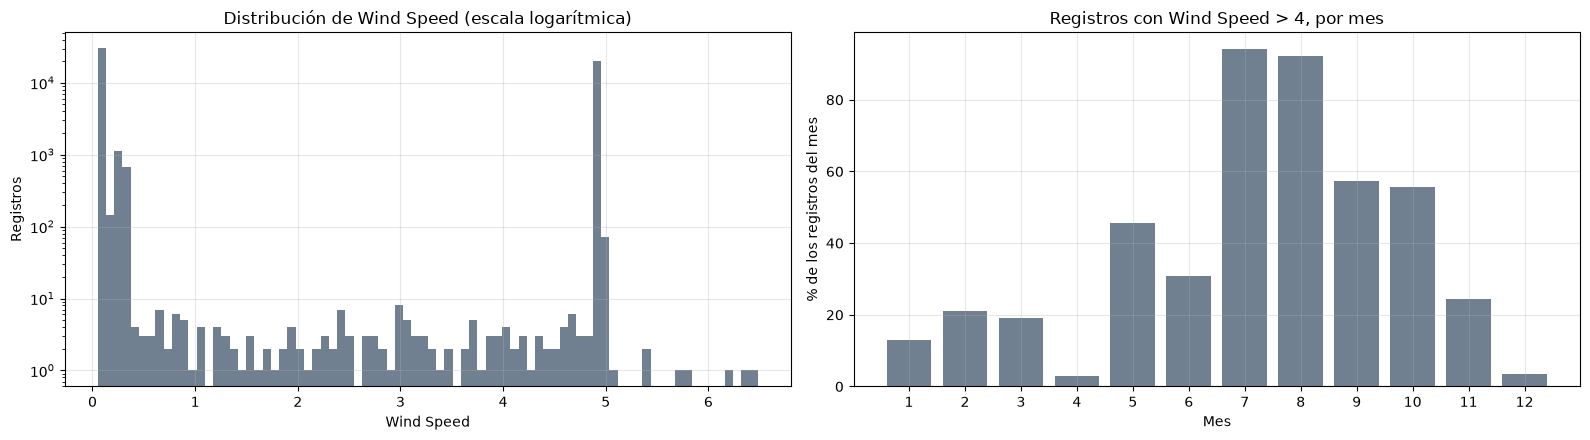

In [8]:
viento = df.set_index("DateTime")["Wind Speed"]
print(f"Registros con viento < 1: {(viento < 1).mean():.1%} · entre 1 y 4: {viento.between(1, 4).mean():.2%} · "
      f"> 4: {(viento > 4).mean():.1%}")
print(f"Veces que cambia de un estado al otro en el año: {int((viento.gt(2).astype(int).diff().abs() > 0).sum())}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(viento, bins=80, color="slategray")
axes[0].set_yscale("log")
axes[0].set(title="Distribución de Wind Speed (escala logarítmica)", xlabel="Wind Speed", ylabel="Registros")
alto = viento.gt(4).groupby(viento.index.month).mean() * 100
axes[1].bar(alto.index, alto.values, color="slategray")
axes[1].set(title="Registros con Wind Speed > 4, por mes", xlabel="Mes", ylabel="% de los registros del mes",
            xticks=range(1, 13))
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Una velocidad del viento real pasa por todos los valores intermedios. Aquí no: casi todos los registros
están cerca de 0.08 o por encima de 4.9, y menos del 0.2 % cae en medio. Además, la proporción del estado
alto cambia mucho de un mes a otro (más del 90 % de los registros en julio y agosto, menos del 5 % en
abril y diciembre).

La variable se comporta como un indicador de dos estados, no como una medición continua. Puede ser un
cambio de sensor, una codificación propia del SCADA o un error de exportación; la fuente no lo explica.
**Implicancia:** no se interpreta como velocidad del viento en el paper. En la preparación se evalúa si
aporta como indicador de dos estados.

## Valores atípicos (criterio IQR)

Un valor es atípico si está por debajo de Q1 − 1.5·IQR o por encima de Q3 + 1.5·IQR. Para cada variable
se cuenta cuántos hay y en qué meses y horas se concentran.

In [9]:
filas = []
for col in numericas.columns:
    q1, q3 = numericas[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (numericas[col] < q1 - 1.5 * iqr) | (numericas[col] > q3 + 1.5 * iqr)
    momentos = df.loc[fuera, "DateTime"]
    filas.append({
        "Variable": col,
        "Atípicos": int(fuera.sum()),
        "% del total": round(100 * fuera.mean(), 1),
        "Meses con más atípicos": ", ".join(map(str, momentos.dt.month.value_counts().head(3).index)),
        "Horas con más atípicos": ", ".join(map(str, momentos.dt.hour.value_counts().head(3).index)),
    })
display(pd.DataFrame(filas).set_index("Variable"))

,Atípicos,% del total,Meses con más atípicos,Horas con más atípicos
Variable,,,,
Temperature,142,0.3,"7, 8","14, 15, 12"
Humidity,291,0.6,"7, 8, 5","14, 15, 16"
Wind Speed,0,0.0,,
general diffuse flows,2315,4.4,"5, 7, 6","13, 12, 14"
diffuse flows,4571,8.7,"5, 6, 3","17, 16, 15"
Zone 1 Power Consumption,0,0.0,,
Zone 2 Power Consumption,7,0.0,"8, 7","20, 19"
Zone 3 Power Consumption,1191,2.3,"7, 8","20, 21, 19"


- **Zona 1** no tiene atípicos y la **Zona 2** solo 7, en julio y agosto entre las 19 y las 20 h: son picos de
  verano dentro de un rango plausible.
- **Zona 3** tiene 1,191 (2.3 %), todos en julio y agosto y en las horas pico (de 19 a 21 h). Son la demanda
  real de la temporada, no errores de medición.
- **Radiación difusa:** sus atípicos son los valores del mediodía y de la tarde en los meses con más sol (de
  marzo a julio), dentro de una distribución sesgada por las noches, cuando vale casi 0.
- **Temperatura y humedad:** pocos casos (0.3 % y 0.6 %), en las tardes de verano y dentro de rangos posibles
  para Tetuán.
- **Velocidad del viento:** el IQR no detecta atípicos porque sus dos estados ocupan todo el rango
  intercuartílico. Su problema es otro (ver arriba).

La decisión sobre los atípicos se toma en la preparación: no se elimina ni se recorta ningún valor.

## Comportamiento temporal de los picos de consumo

Además de la media, la mediana y el IQR, se analiza **cuándo** ocurren los picos de cada zona: a lo largo del año, por hora del día, por día de la semana y por mes. Se grafica el máximo (pico) y, como referencia, el promedio.

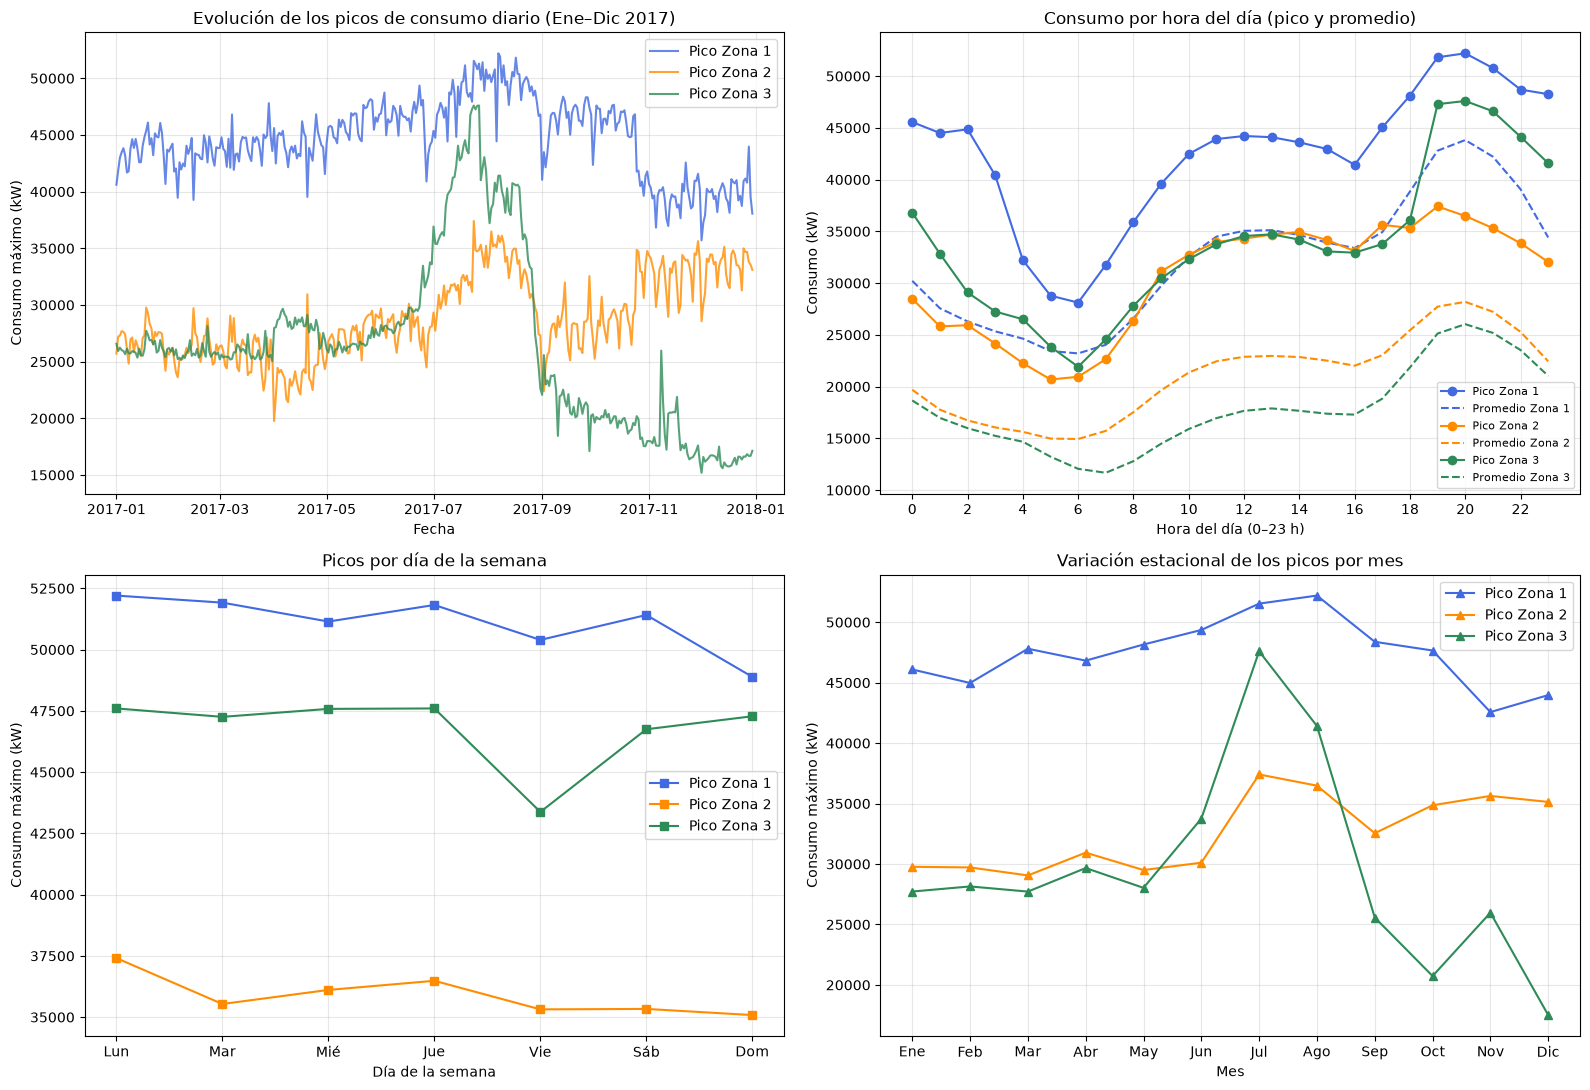

Hora de mayor consumo promedio por zona:
Zone 1 Power Consumption    20
Zone 2 Power Consumption    20
Zone 3 Power Consumption    20
dtype: int32


In [10]:
df_eda = df.copy()
df_eda["Hora"] = df_eda["DateTime"].dt.hour
df_eda["Mes"] = df_eda["DateTime"].dt.month
df_eda["DiaSemana"] = df_eda["DateTime"].dt.day_of_week

zone_labels = ["Zona 1", "Zona 2", "Zona 3"]
colors = ["royalblue", "darkorange", "seagreen"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Picos diarios a lo largo del año
picos_diarios = df_eda.groupby(df_eda["DateTime"].dt.date)[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[0, 0].plot(picos_diarios.index, picos_diarios[col], label=f"Pico {label}", color=color, alpha=0.8)
axes[0, 0].set_title("Evolución de los picos de consumo diario (Ene–Dic 2017)")
axes[0, 0].set_xlabel("Fecha")
axes[0, 0].set_ylabel("Consumo máximo (kW)")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Perfil por hora del día: pico (línea continua) y promedio (línea punteada)
picos_horarios = df_eda.groupby("Hora")[ZONES].max()
prom_horarios = df_eda.groupby("Hora")[ZONES].mean()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[0, 1].plot(picos_horarios.index, picos_horarios[col], label=f"Pico {label}", color=color, marker="o")
    axes[0, 1].plot(prom_horarios.index, prom_horarios[col], label=f"Promedio {label}", color=color, linestyle="--")
axes[0, 1].set_title("Consumo por hora del día (pico y promedio)")
axes[0, 1].set_xlabel("Hora del día (0–23 h)")
axes[0, 1].set_ylabel("Consumo (kW)")
axes[0, 1].set_xticks(range(0, 24, 2))
axes[0, 1].legend(fontsize=8)
axes[0, 1].grid(alpha=0.3)

# 3. Picos por día de la semana
dias_labels = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
picos_semanales = df_eda.groupby("DiaSemana")[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[1, 0].plot(dias_labels, picos_semanales[col], label=f"Pico {label}", color=color, marker="s")
axes[1, 0].set_title("Picos por día de la semana")
axes[1, 0].set_xlabel("Día de la semana")
axes[1, 0].set_ylabel("Consumo máximo (kW)")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 4. Picos por mes
meses_labels = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
picos_mensuales = df_eda.groupby("Mes")[ZONES].max()
for col, label, color in zip(ZONES, zone_labels, colors):
    axes[1, 1].plot(meses_labels, picos_mensuales[col], label=f"Pico {label}", color=color, marker="^")
axes[1, 1].set_title("Variación estacional de los picos por mes")
axes[1, 1].set_xlabel("Mes")
axes[1, 1].set_ylabel("Consumo máximo (kW)")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Hora en que cada zona alcanza su mayor consumo promedio
print("Hora de mayor consumo promedio por zona:")
print(prom_horarios.idxmax())

**Interpretación de los picos (H1 se confirma):**

- **Por hora:** las tres zonas tienen su mínimo entre las 5 y las 7 h y su máximo a las 20 h. El pico del día
  es al anochecer.
- **A lo largo del año:** la Zona 3 se dispara en julio y agosto y cae de golpe a fines de agosto. A fines de
  octubre, la Zona 1 baja y la Zona 2 sube al mismo tiempo: es una transferencia de carga entre
  subestaciones, que se analiza más abajo.
- **Por día de la semana:** los picos de las Zonas 1 y 2 son algo menores el domingo y la Zona 3 tiene su pico
  más bajo el viernes. Como son máximos, dependen de pocos días; las diferencias de fondo entre días
  laborables y fines de semana se miden con promedios en la firma de carga.
- **Por mes:** la Zona 3 alcanza en julio su pico anual, muy por encima del resto del año. La Zona 1 tiene sus
  picos en verano. La Zona 2 los tiene en julio y en noviembre-diciembre; los de fin de año se deben a la
  transferencia de carga.

Los picos siguen patrones diarios y estacionales, no son errores aislados. Por eso el modelo necesita el
calendario y el consumo de periodos anteriores.

## Las tres zonas: firma de carga

La industria eléctrica distingue qué tipo de demanda tiene una zona por la forma de su curva de carga:
cuándo sube y baja durante el día, si cae el fin de semana, cuánto responde al calor y cómo cambia en los
días especiales. El factor de carga (media / máximo) resume qué tan pareja es la demanda: es alto cuando
el consumo es estable y bajo cuando hay picos muy por encima de lo habitual.

In [11]:
display(perfiles.firma_de_carga(df).round(2))

,Zona 1,Zona 2,Zona 3
Parte de la demanda de la ciudad (%),45.41,29.54,25.04
Factor de carga (media / máximo),0.62,0.56,0.37
Domingo de día / laborable (9-17 h),0.91,0.81,1.01
Julio / promedio anual,1.11,1.15,1.58
Mes más alto / mes más bajo,1.26,1.40,2.55
Sensibilidad al calor en verano (%/°C),0.95,3.03,6.94
Ramadán de día / mes previo (9-16 h),0.98,0.93,0.99
Ramadán de madrugada / mes previo (0-4 h),1.44,1.41,1.45


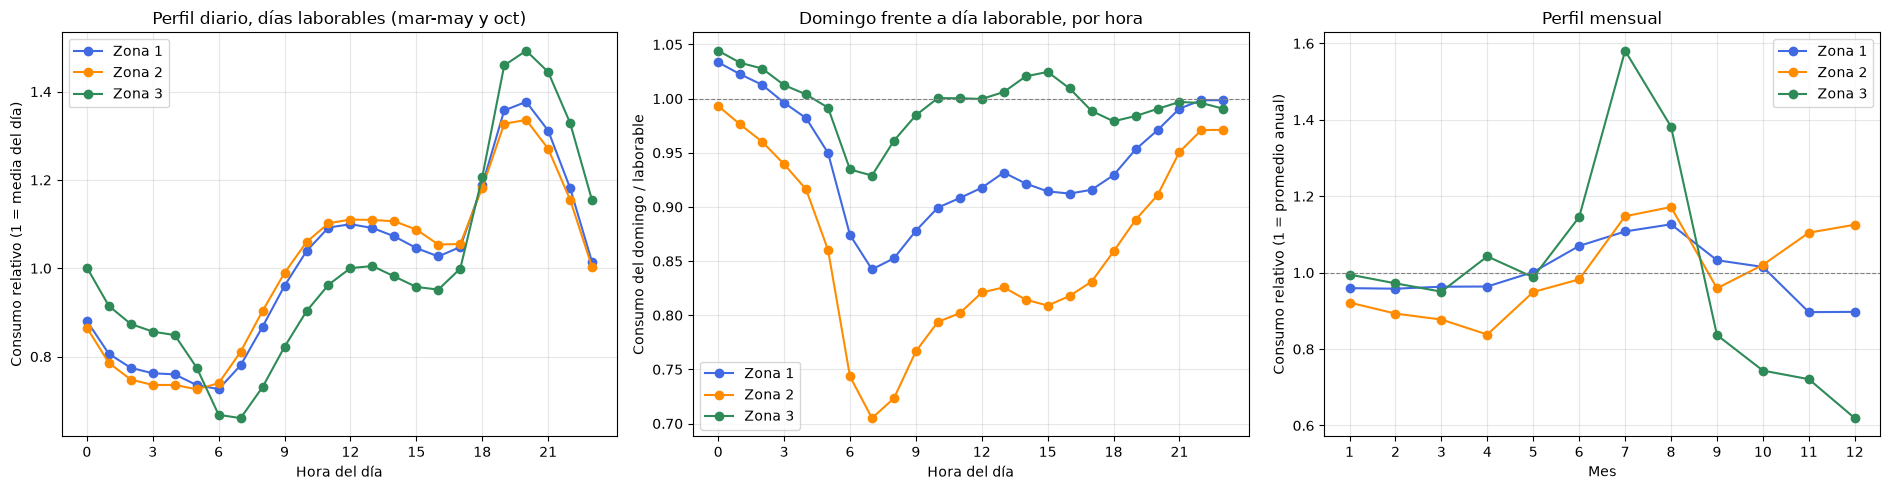

In [12]:
c = perfiles.consumo_por_zona(df)
temporada_media = c[c.index.month.isin(perfiles.TEMPORADA_MEDIA)]
laborable = temporada_media[temporada_media.index.day_of_week < 5]
domingo = temporada_media[temporada_media.index.day_of_week == 6]
domingo_vs_laborable = domingo.groupby(domingo.index.hour).mean() / laborable.groupby(laborable.index.hour).mean()
diario, mensual = perfiles.perfil_diario(df), perfiles.perfil_mensual(df)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for zona in perfiles.NOMBRES:
    axes[0].plot(diario.index, diario[zona], marker="o", color=COLORES[zona], label=zona)
    axes[1].plot(domingo_vs_laborable.index, domingo_vs_laborable[zona], marker="o", color=COLORES[zona], label=zona)
    axes[2].plot(mensual.index, mensual[zona], marker="o", color=COLORES[zona], label=zona)
axes[0].set(title="Perfil diario, días laborables (mar-may y oct)", xlabel="Hora del día",
            ylabel="Consumo relativo (1 = media del día)", xticks=range(0, 24, 3))
axes[1].set(title="Domingo frente a día laborable, por hora", xlabel="Hora del día",
            ylabel="Consumo del domingo / laborable", xticks=range(0, 24, 3))
axes[2].set(title="Perfil mensual", xlabel="Mes", ylabel="Consumo relativo (1 = promedio anual)",
            xticks=range(1, 13))
for ax in axes[1:]:
    ax.axhline(1, color="gray", lw=0.8, ls="--")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cada zona tiene una firma distinta (**H2 se confirma**):

- **Zona 3, costera y de veraneo.** Tiene el factor de carga más bajo, la mayor diferencia entre meses
  (2.55 veces del mes más alto al más bajo) y la mayor sensibilidad al calor. Su consumo no baja el
  domingo. Es coherente con Smir, la franja costera turística al norte de Tetuán.
- **Zona 2, ritmo laboral.** Es la que más cae el domingo de día (−19 %) y la única que baja de día en
  Ramadán. Su demanda sigue la actividad de comercio, administración o industria.
- **Zona 1, red urbana mixta.** Concentra el 45 % de la demanda, es la más estable y combina rasgos de
  las otras dos.

La identidad de las zonas no está confirmada por la fuente: es una hipótesis de trabajo. El razonamiento
completo está en [`docs/investigacion.md`](https://github.com/R0SEWT/tetouan-power-forecast/blob/develop/docs/investigacion.md).

## Un cambio estructural: transferencia de carga entre la Zona 1 y la Zona 2

En el gráfico de picos, a fines de octubre la Zona 1 baja y la Zona 2 sube a la vez. Se comparan las dos
semanas anteriores y las dos posteriores al 25 de octubre, y ese día frente al mismo momento del día
anterior.

Consumo medio: 11 al 24 de octubre (antes) frente al 26 de octubre al 8 de noviembre (después)


,antes (kW),después (kW),cambio (%)
Zona 1,33623.8,29419.3,-12.5
Zona 2,21109.2,23489.6,11.3
Zona 3,13291.6,12410.0,-6.6
Zona 1 + Zona 2,54733.0,52908.9,-3.3


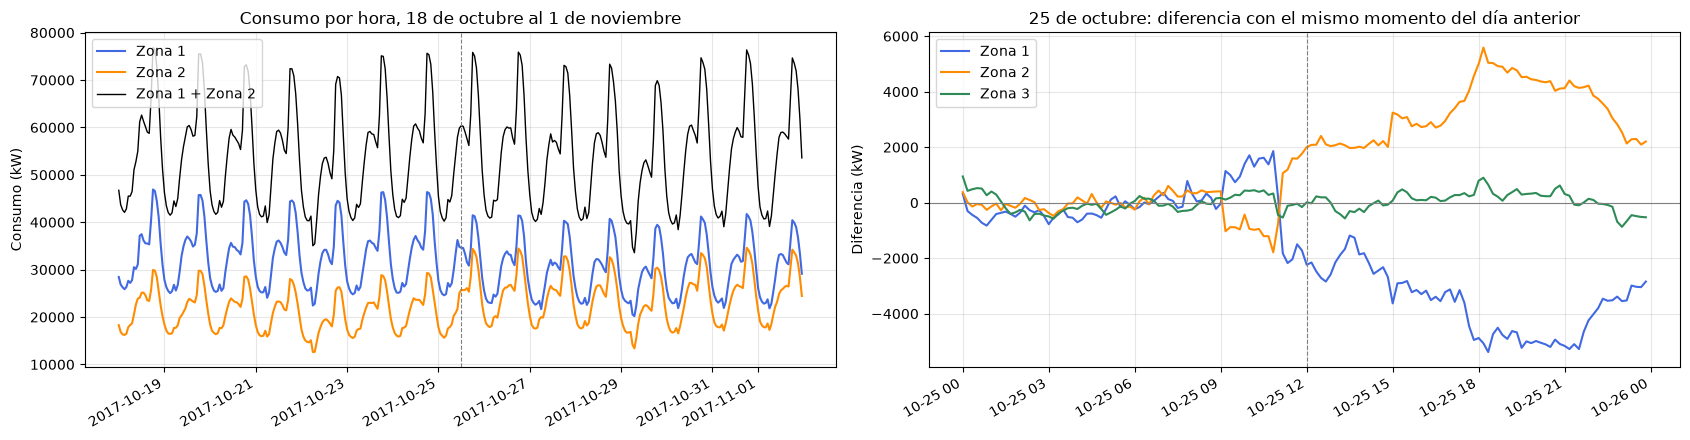

In [13]:
print("Consumo medio: 11 al 24 de octubre (antes) frente al 26 de octubre al 8 de noviembre (después)")
display(perfiles.comparar_periodos(df).round(1))

por_hora = c.loc["2017-10-18":"2017-11-01"].resample("h").mean()
dia = c.loc["2017-10-25"]
frente_a_ayer = dia - c.shift(PERIODOS_DIA).loc[dia.index]  # frente al mismo momento del día anterior

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for zona in ["Zona 1", "Zona 2"]:
    axes[0].plot(por_hora.index, por_hora[zona], color=COLORES[zona], label=zona)
axes[0].plot(por_hora.index, por_hora["Zona 1"] + por_hora["Zona 2"], color="black", lw=1, label="Zona 1 + Zona 2")
axes[0].set(title="Consumo por hora, 18 de octubre al 1 de noviembre", ylabel="Consumo (kW)")
for zona in perfiles.NOMBRES:
    axes[1].plot(frente_a_ayer.index, frente_a_ayer[zona], color=COLORES[zona], label=zona)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(title="25 de octubre: diferencia con el mismo momento del día anterior", ylabel="Diferencia (kW)")
for ax in axes:
    ax.axvline(pd.Timestamp("2017-10-25 12:00"), color="gray", ls="--", lw=0.8)
    ax.legend()
    ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

El 25 de octubre, cerca del mediodía, la Zona 1 cae y la Zona 2 sube en espejo, mientras la suma de ambas
casi no cambia: baja 3.3 %, en línea con la baja estacional que también tiene la Zona 3. Es una
**transferencia de carga entre subestaciones**: parte de los clientes de la Zona 1 pasaron a alimentarse desde
la Zona 2.

- Es justamente el tipo de maniobra que el pronóstico busca anticipar, y aparece en los datos.
- **La prueba (desde el 6 de noviembre) y el final de la validación caen después del cambio:** la Zona 1 queda
  alrededor de 12 % más baja y la Zona 2, 11 % más alta. Los rezagos recientes reflejan el nuevo nivel de
  inmediato; el rezago diario y el semanal tardan uno y siete días en ponerse al día.
- La subida de la Zona 2 en noviembre y diciembre que se ve en el perfil mensual no es estacional: es la
  transferencia.
- Conviene evaluar los errores antes y después del 25 de octubre por separado, y no asumir que los clientes de
  cada zona son siempre los mismos.

## Clima y consumo

Se compara el consumo medio de cada día con su temperatura media, separando el verano (de junio a
septiembre) del resto del año, y se mide la relación lineal entre todas las variables.

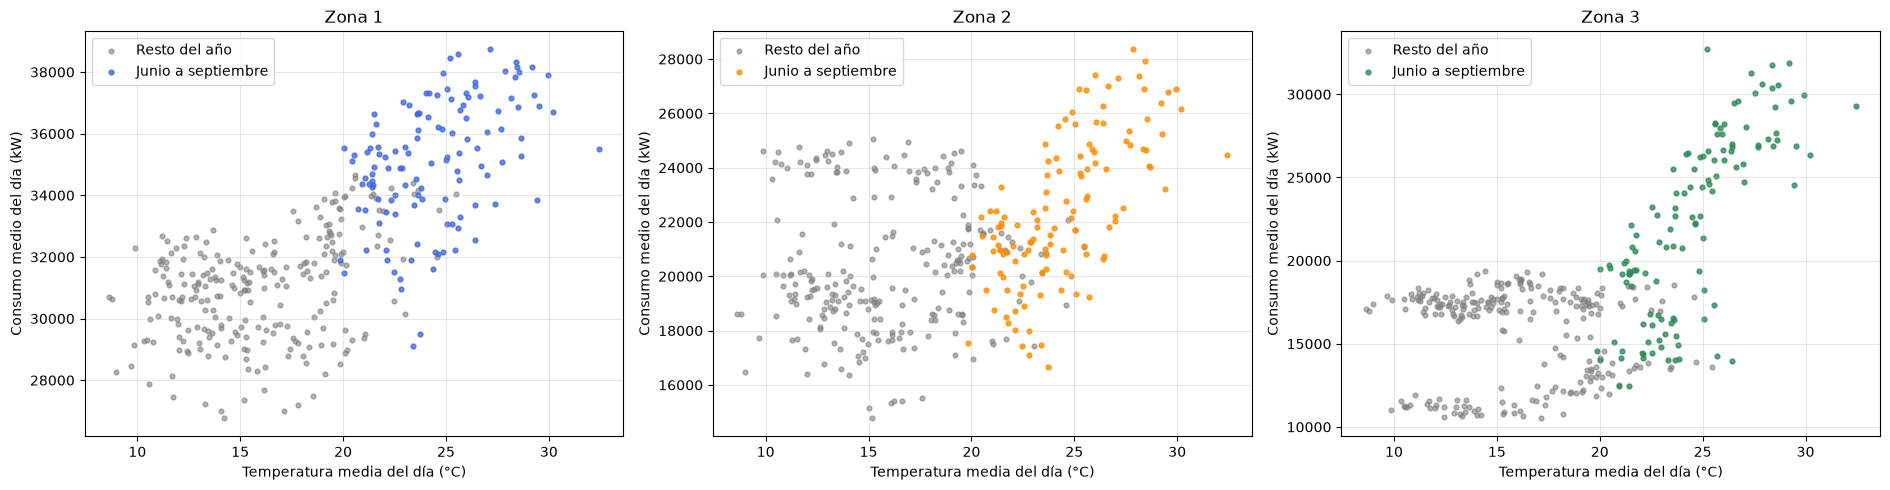

,Verano (jun-sep),Invierno (dic-feb)
Cambio del consumo por °C (%),,
Zona 1,0.95,-0.25
Zona 2,3.03,0.47
Zona 3,6.94,-1.76


In [14]:
por_dia = df.set_index("DateTime").resample("D").mean()
verano = por_dia.index.month.isin([6, 7, 8, 9])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, zona, col in zip(axes, perfiles.NOMBRES, ZONES):
    ax.scatter(por_dia.loc[~verano, "Temperature"], por_dia.loc[~verano, col], s=12, alpha=0.6, color="gray",
               label="Resto del año")
    ax.scatter(por_dia.loc[verano, "Temperature"], por_dia.loc[verano, col], s=12, alpha=0.8, color=COLORES[zona],
               label="Junio a septiembre")
    ax.set(title=zona, xlabel="Temperatura media del día (°C)", ylabel="Consumo medio del día (kW)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

sensibilidad = pd.DataFrame({
    "Verano (jun-sep)": perfiles.sensibilidad_temperatura(df, [6, 7, 8, 9]),
    "Invierno (dic-feb)": perfiles.sensibilidad_temperatura(df, [12, 1, 2]),
})
display(sensibilidad.round(2).rename_axis("Cambio del consumo por °C (%)"))

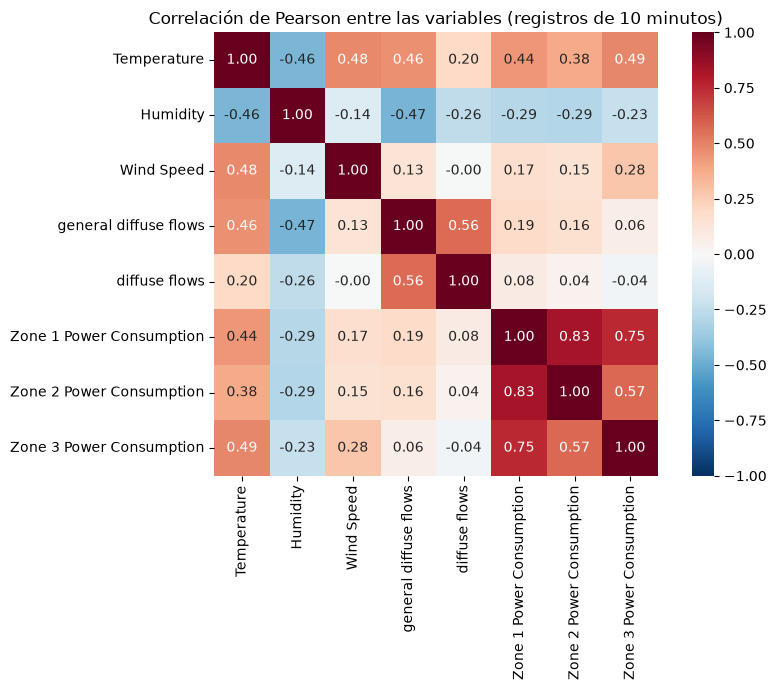

In [15]:
plt.figure(figsize=(9, 7))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlación de Pearson entre las variables (registros de 10 minutos)")
plt.tight_layout()
plt.show()

**Interpretación (H3 se confirma, con matices):**

- En verano el consumo sube con la temperatura en las tres zonas, y mucho más en la Zona 3: casi 7 % por cada
  grado, frente a 3 % en la Zona 2 y 1 % en la Zona 1. Es el aire acondicionado, sumado a la población
  estacional de la costa.
- Fuera del verano, la relación casi desaparece (entre −1.8 y +0.5 % por grado). En la Zona 3 se ven dos nubes
  separadas a igual temperatura: la de enero a mayo y la de octubre a diciembre, con mucho menos consumo. Lo
  que cambia ahí no es el clima, sino la cantidad de gente en la zona. En la Zona 2, la nube alta de fin de año
  es la transferencia de carga.
- La correlación lineal de la temperatura con el consumo es moderada (de 0.38 a 0.49) y las tres zonas están
  muy correlacionadas entre sí (0.83 entre la 1 y la 2). Por eso los rezagos de las otras zonas aportan como
  predictoras.
- Para un horizonte de una hora, el clima observado en t aporta poco frente al consumo reciente, que ya
  incorpora su efecto (ver la ablación en la preparación). Su valor está en anticipar los días de calor en la
  Zona 3.

## Días especiales: Ramadán y feriados

El calendario gregoriano (mes, día del año, día de la semana) no captura los días cuya fecha depende del
calendario hijri: Ramadán y los feriados religiosos cambian de fecha cada año. En 2017, Ramadán fue del 27
de mayo al 25 de junio en Marruecos; se comparan sus días interiores con las cuatro semanas anteriores.

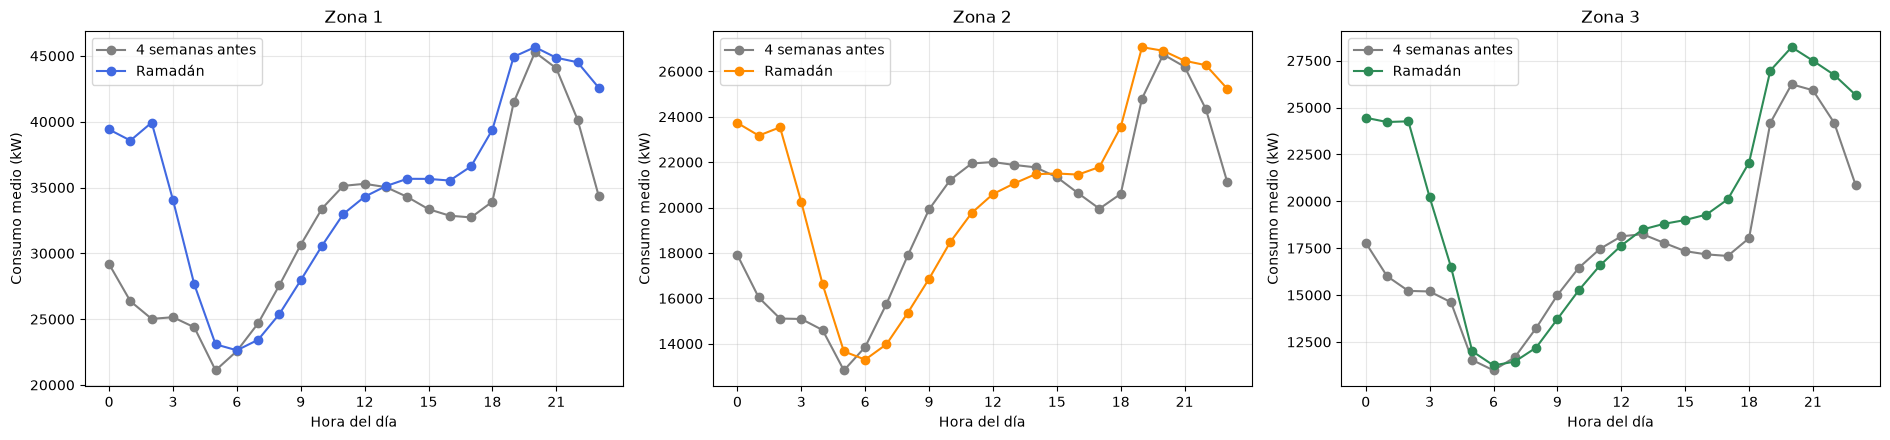

Feriados de 2017 en día laborable: consumo del feriado / mismo día de semana sin feriado


,Zona 1,Zona 2,Zona 3
11-ene · Manifiesto de la Independencia,0.97,0.92,0.96
1-may · Día del Trabajo,0.91,0.92,0.97
26-jun · Eid al-Fitr,0.88,0.80,0.99
27-jun · Eid al-Fitr,0.82,0.77,0.94
14-ago · Oued Ed-Dahab,0.95,0.97,1.03
21-ago · Día de la Juventud,1.02,1.03,1.18
1-sep · Eid al-Adha,0.83,0.73,0.77
6-nov · Marcha Verde,0.94,0.95,0.91
1-dic · Mawlid,0.93,0.88,0.86


In [16]:
ramadan = c.loc[slice(*perfiles.RAMADAN)]
previo = c.loc[slice(*perfiles.PREVIO_RAMADAN)]

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
for ax, zona in zip(axes, perfiles.NOMBRES):
    ax.plot(previo.groupby(previo.index.hour)[zona].mean(), marker="o", color="gray", label="4 semanas antes")
    ax.plot(ramadan.groupby(ramadan.index.hour)[zona].mean(), marker="o", color=COLORES[zona], label="Ramadán")
    ax.set(title=zona, xlabel="Hora del día", ylabel="Consumo medio (kW)", xticks=range(0, 24, 3))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Feriados de 2017 en día laborable: consumo del feriado / mismo día de semana sin feriado")
display(perfiles.efecto_feriados(df).round(2))

**Interpretación (H4 se confirma):**

- **Ramadán cambia la forma del día, no solo el nivel.** De madrugada (de 0 a 3 h) el consumo sube entre 41 y
  45 % en las tres zonas, por la comida previa al amanecer, y cae a las 3-4 h. De mañana es más bajo, sobre
  todo en la Zona 2, porque la jornada empieza más tarde. A la tarde sube antes y se mantiene alto hasta la
  medianoche.
- **Los feriados bajan el consumo, pero no en todas las zonas por igual.** En Eid al-Adha cae 17 % en la
  Zona 1, 27 % en la Zona 2 y 23 % en la Zona 3. En la Zona 2, que sigue la actividad laboral, bajan casi
  todos los feriados. En la Zona 3, los feriados de verano la suben (+18 % el 21 de agosto).
- Ni el mes ni el día de la semana capturan estos días: Ramadán y los feriados religiosos cambian de fecha
  cada año, y los feriados civiles rompen el patrón semanal. En la preparación conviene agregar indicadores
  de Ramadán y de feriado, y evaluar esos días por separado.

## Qué tan predecible es cada zona

La autocorrelación mide cuánto se parece la serie a sí misma desplazada en el tiempo. Las referencias
ingenuas convierten esa idea en un pronóstico sin aprendizaje. Para un horizonte de una hora hay tres
habituales:

- **persistencia:** en una hora se consumirá lo mismo que ahora (t);
- **ayer:** lo mismo que a esa hora de ayer (t+6−144);
- **semana pasada:** lo mismo que a esa hora hace una semana (t+6−1008).

In [17]:
desfases = {"1 hora (6 periodos)": 6, "1 día (144)": 144, "1 semana (1008)": 1008}
autocorrelacion = pd.DataFrame({nombre: c.apply(lambda s, n=n: s.autocorr(n)) for nombre, n in desfases.items()}).T
display(autocorrelacion.round(3).rename_axis("Autocorrelación"))

mape = pd.DataFrame({
    zona: perfiles.errores_referencias(perfiles.referencias_ingenuas(df, z))["MAPE (%)"]
    for z, zona in enumerate(perfiles.NOMBRES, start=1)
})
display(mape.round(2).rename_axis("MAPE (%) en todo 2017"))

,Zona 1,Zona 2,Zona 3
Autocorrelación,,,
1 hora (6 periodos),0.913,0.931,0.951
1 día (144),0.962,0.934,0.987
1 semana (1008),0.952,0.936,0.956


,Zona 1,Zona 2,Zona 3
MAPE (%) en todo 2017,,,
persistencia,6.82,6.99,8.00
ayer,4.17,6.40,4.13
semana_pasada,4.62,6.17,7.34


**Interpretación (H5 se confirma):**

- Las tres zonas se parecen mucho a sí mismas un día antes (autocorrelación de 0.93 a 0.99): el ciclo diario
  domina. En la Zona 2, el desfase de una semana pesa tanto como el de un día, por su ritmo laboral.
- La persistencia es la peor referencia en las tres zonas.
- La mejor referencia del año es "ayer" en las Zonas 1 y 3 y "semana pasada" en la Zona 2. Ganarle solo a la
  persistencia no demuestra nada: el modelo tiene que superar a la mejor referencia de cada zona.

## Hallazgos de la exploración

1. **Calidad:** el archivo está completo: 52,416 registros cada 10 minutos, sin nulos, duplicados ni huecos.
   Solo falta el 31 de diciembre. Los problemas son de formato (DateTime como texto y nombres con espacios
   dobles) y el silver los corrige.
2. **Viento:** `Wind Speed` se comporta como un indicador de dos estados, no como una velocidad. No se
   interpreta físicamente y en la preparación se evalúa como indicador.
3. **Atípicos:** son demanda real (picos de verano de la Zona 3) y horas de sol (radiación). No se eliminan.
4. **Ciclo diario (H1):** las tres zonas tienen su mínimo entre las 5 y las 7 h y su pico a las 20 h.
5. **Tres firmas distintas (H2):** la Zona 1 es urbana, mixta y estable; la Zona 2, laboral; la Zona 3, costera
   y de veraneo.
6. **Cambio estructural:** el 25 de octubre hubo una transferencia de carga de la Zona 1 a la Zona 2. La
   prueba cae después del cambio.
7. **Clima (H3):** importa en verano, sobre todo en la Zona 3. El resto del año pesa más la población de cada
   zona que la temperatura.
8. **Días especiales (H4):** Ramadán cambia la forma del día y los feriados bajan el consumo, sobre todo en la
   Zona 2. El calendario gregoriano no los captura.
9. **Referencias ingenuas (H5):** la persistencia es la más débil. La mejor es "ayer" en las Zonas 1 y 3 y
   "semana pasada" en la Zona 2.

**Qué se lleva a la preparación:**

- indicadores de Ramadán y de feriado;
- el rezago de la semana pasada;
- `Wind Speed` como indicador de dos estados;
- cuidado con el calendario anual, que con un solo año identifica épocas;
- evaluar por separado antes y después de la transferencia de carga.

# Preparación de los Datos

En esta fase se transforman los datos para que respondan al problema definido: estimar el consumo de la Zona 1 una hora adelante, usando solo información disponible en el momento de predecir.

La preparación se muestra con la **Zona 1**, el caso principal. El medallón aplica exactamente lo mismo a
las Zonas 2 y 3 (`gold/t6_zona2.parquet` y `gold/t6_zona3.parquet`), cada una con su propio rezago diario
y sus estadísticas móviles.

## Cambios respecto a la entrega anterior

- Se eliminaron las variables creadas a partir de hipótesis no demostradas con los datos (Is_Heatwave, Muggy_Comfort_Risk, Dry_Heat_Risk, Is_Wind).
- Se transformó DateTime en variables de tiempo: hora, minuto del día, día, mes, día de la semana, día del año y fin de semana, con codificación cíclica.
- Se revisaron los picos de las tres zonas considerando su comportamiento temporal (por día, hora, día de la semana y mes).
- Se utilizará únicamente Zone 1 como variable objetivo; Zone 2 y Zone 3 se usan como predictoras.
- Se predecirá el consumo 6 periodos adelante, equivalente a 1 hora.

## Tratamiento de valores atípicos

- **Zone 3 Power Consumption:** los registros por encima del límite superior del IQR se concentran en julio y agosto, los meses de más calor. Corresponden a demanda real de verano, no a errores de medición.
- **general diffuse flows y diffuse flows:** la radiación vale casi 0 toda la noche y sube mucho al mediodía; su distribución sesgada sigue el ciclo día/noche.
- **Temperature y Humidity:** son pocos casos y están dentro de rangos posibles para Tetouan.
- **Zone 1** no tiene outliers y **Zone 2** solo unos pocos.

**Decisión:** no se elimina ni se recorta ningún valor. Todos son mediciones plausibles, y quitar los picos haría que el modelo subestime justo los periodos de mayor demanda, que son los que el negocio necesita anticipar.

## Variables descartadas

En la entrega anterior se crearon variables basadas en umbrales definidos manualmente (Is_Heatwave, Muggy_Comfort_Risk, Dry_Heat_Risk, Is_Wind). Se eliminaron porque esos umbrales eran hipótesis no demostradas con los datos. En su lugar, Temperature, Humidity y Wind Speed se conservan como variables continuas, para que el modelo aprenda directamente su relación con el consumo.

## Selección de la variable objetivo

Cada zona se pronostica por separado con el mismo pipeline (ver la comprensión del negocio y la firma de
carga). No se usa un modelo multisalida, porque las zonas no comparten su comportamiento a lo largo del
año: la Zona 3 tiene una estacionalidad de verano que las otras no tienen, y la Zona 2 un ciclo semanal
más marcado.

Las otras dos zonas no se descartan: entran como **variables predictoras** a través de sus rezagos,
porque su consumo reciente aporta información sobre la zona que se predice.

## Unidad de análisis y variable objetivo

- **Unidad de análisis:** un periodo de 10 minutos en la ciudad de Tetouan. Cada fila contiene el clima observado y el consumo de las tres zonas en ese periodo.
- **Variable objetivo:** el consumo de la zona una hora después (aquí, la Zona 1) (`Target_Zone1_t_plus_6`, es decir, 6 periodos adelante).
- **Momento de predicción:** al cierre del periodo t, usando solo información disponible hasta t.

## Variables temporales y codificación

El consumo eléctrico sigue ciclos diarios, semanales y anuales, por lo que se extraen componentes de DateTime: hora, minuto del día, día, mes, día de la semana, día del año y fin de semana.

El dataset no contiene variables categóricas originales. Sin embargo, las variables de tiempo son cíclicas (las 23:50 están cerca de las 00:00, y el domingo cerca del lunes), por lo que se codifican con seno y coseno para que el modelo capture esa continuidad.

In [18]:
# Componentes temporales
df["Hour"] = df["DateTime"].dt.hour
df["MinuteOfDay"] = df["DateTime"].dt.hour * 60 + df["DateTime"].dt.minute
df["Day"] = df["DateTime"].dt.day
df["Month"] = df["DateTime"].dt.month
df["DayOfWeek"] = df["DateTime"].dt.day_of_week          # 0 = lunes, 6 = domingo
df["DayOfYear"] = df["DateTime"].dt.day_of_year
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)   # sábado y domingo

# Codificación cíclica (seno / coseno)
# Ciclo diario (1 día = 1440 minutos)
df["Time_Sin"] = np.sin(2 * np.pi * df["MinuteOfDay"] / 1440)
df["Time_Cos"] = np.cos(2 * np.pi * df["MinuteOfDay"] / 1440)
# Ciclo semanal (7 días)
df["Week_Sin"] = np.sin(2 * np.pi * df["DayOfWeek"] / 7)
df["Week_Cos"] = np.cos(2 * np.pi * df["DayOfWeek"] / 7)
# Ciclo anual (365 días)
df["Year_Sin"] = np.sin(2 * np.pi * (df["DayOfYear"] - 1) / 365)
df["Year_Cos"] = np.cos(2 * np.pi * (df["DayOfYear"] - 1) / 365)

# Verificación de IsWeekend: debe marcar solo sábado (5) y domingo (6)
print(df.groupby("DayOfWeek")["IsWeekend"].max())

display(df[["DateTime", "Hour", "Day", "Month", "DayOfWeek", "IsWeekend",
            "Time_Sin", "Time_Cos", "Week_Sin", "Week_Cos"]].head())

DayOfWeek
0    0
1    0
2    0
3    0
4    0
5    1
6    1
Name: IsWeekend, dtype: int64


,DateTime,Hour,Day,Month,DayOfWeek,IsWeekend,Time_Sin,Time_Cos,Week_Sin,Week_Cos
0,2017-01-01 00:00:00,0,1,1,6,1,0.000000,1.000000,-0.781831,0.62349
1,2017-01-01 00:10:00,0,1,1,6,1,0.043619,0.999048,-0.781831,0.62349
2,2017-01-01 00:20:00,0,1,1,6,1,0.087156,0.996195,-0.781831,0.62349
3,2017-01-01 00:30:00,0,1,1,6,1,0.130526,0.991445,-0.781831,0.62349
4,2017-01-01 00:40:00,0,1,1,6,1,0.173648,0.984808,-0.781831,0.62349


**Limitación:** el dataset abarca un solo año. Como la partición es cronológica, el modelo nunca verá noviembre y diciembre durante el entrenamiento, por lo que el patrón anual (Year_Sin, Year_Cos, DayOfYear, Month) no se puede aprender completamente.

## Variable objetivo y rezagos

Los registros son cada 10 minutos. Se toma **t** como el periodo actual; **t+n** indica n periodos adelante y **t−n**, n periodos atrás.

- **Objetivo:** consumo de la Zona 1 en **t+6** (1 hora después).
- **Rezagos de las tres zonas:** t, t−1 (10 min), t−2 (20 min) y t−6 (1 hora).
- **Rezago diario de Zone 1:** mismo momento del día anterior al periodo que se predice (t+6−144 = t−138). Captura el ciclo diario que se observó en los picos.
- **Estadísticas móviles de Zone 1:** media y desviación estándar de la última hora (t−5 a t).

Todas estas variables usan solo información conocida en t.

In [19]:
HORIZONTE = 6   # 6 periodos de 10 minutos = 1 hora
TARGET = "Target_Zone1_t_plus_6"

# Variable objetivo: consumo de Zone 1 una hora adelante
df[TARGET] = df["Zone 1 Power Consumption"].shift(-HORIZONTE)

# Rezagos de las tres zonas
lags = [0, 1, 2, 6]
for lag in lags:
    suffix = "_t" if lag == 0 else f"_t_minus_{lag}"
    df[f"Zone1{suffix}"] = df["Zone 1 Power Consumption"].shift(lag)
    df[f"Zone2{suffix}"] = df["Zone 2 Power Consumption"].shift(lag)
    df[f"Zone3{suffix}"] = df["Zone 3 Power Consumption"].shift(lag)

# Rezago diario: mismo momento del día anterior al periodo que se predice
df["Zone1_lag_24h"] = df["Zone 1 Power Consumption"].shift(144 - HORIZONTE)

# Estadísticas móviles de la última hora (t-5 a t)
df["Zone1_Rolling_Mean_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).mean()
df["Zone1_Rolling_Std_1h"] = df["Zone 1 Power Consumption"].rolling(window=6).std()

# Eliminación de filas sin historial suficiente o sin objetivo
df_model = df.dropna().reset_index(drop=True)

print(f"Dimensiones del dataset original: {df.shape}")
print(f"Dimensiones del dataset listo para modelar: {df_model.shape}")
print(f"Filas eliminadas: {len(df) - len(df_model)}")

display(df_model[["DateTime", "Zone1_t", "Zone1_t_minus_1", "Zone1_lag_24h",
                  "Zone1_Rolling_Mean_1h", TARGET]].head())

Dimensiones del dataset original: (52416, 38)
Dimensiones del dataset listo para modelar: (52272, 38)
Filas eliminadas: 144


,DateTime,Zone1_t,Zone1_t_minus_1,Zone1_lag_24h,Zone1_Rolling_Mean_1h,Target_Zone1_t_plus_6
0,2017-01-01 23:00:00,32117.46835,33077.46835,34055.69620,34166.075947,26703.79747
1,2017-01-01 23:10:00,31357.97468,32117.46835,29814.68354,33326.582275,26169.11392
2,2017-01-01 23:20:00,30701.77215,31357.97468,29128.10127,32562.025313,25622.27848
3,2017-01-01 23:30:00,29681.01266,30701.77215,28228.86076,31769.113922,24972.15190
4,2017-01-01 23:40:00,28830.37975,29681.01266,27335.69620,30961.012657,24437.46835


Se eliminan las primeras filas, que no tienen historial suficiente para el rezago de 24 horas, y las últimas 6, que no tienen objetivo t+6. No se imputa ningún valor, para no introducir información artificial ni del futuro.

## Correlación de las variables con el objetivo y chequeo de calidad

--- TOP 10 VARIABLES MÁS CORRELACIONADAS CON EL TARGET (t+6) ---
Zone1_lag_24h            0.961645
Zone1_t                  0.912919
Zone1_t_minus_1          0.887717
Zone1_t_minus_2          0.860533
Zone1_Rolling_Mean_1h    0.851158
Zone2_t                  0.765888
Zone2_t_minus_1          0.745149
Zone1_t_minus_6          0.736424
Zone2_t_minus_2          0.722668
Hour                     0.684834
dtype: float64

--- TOP 5 VARIABLES MENOS CORRELACIONADAS (MÁS CERCANAS A 0) ---
DayOfYear    0.006416
Month        0.007684
Day          0.024114
Week_Cos     0.028660
Week_Sin     0.065160
dtype: float64


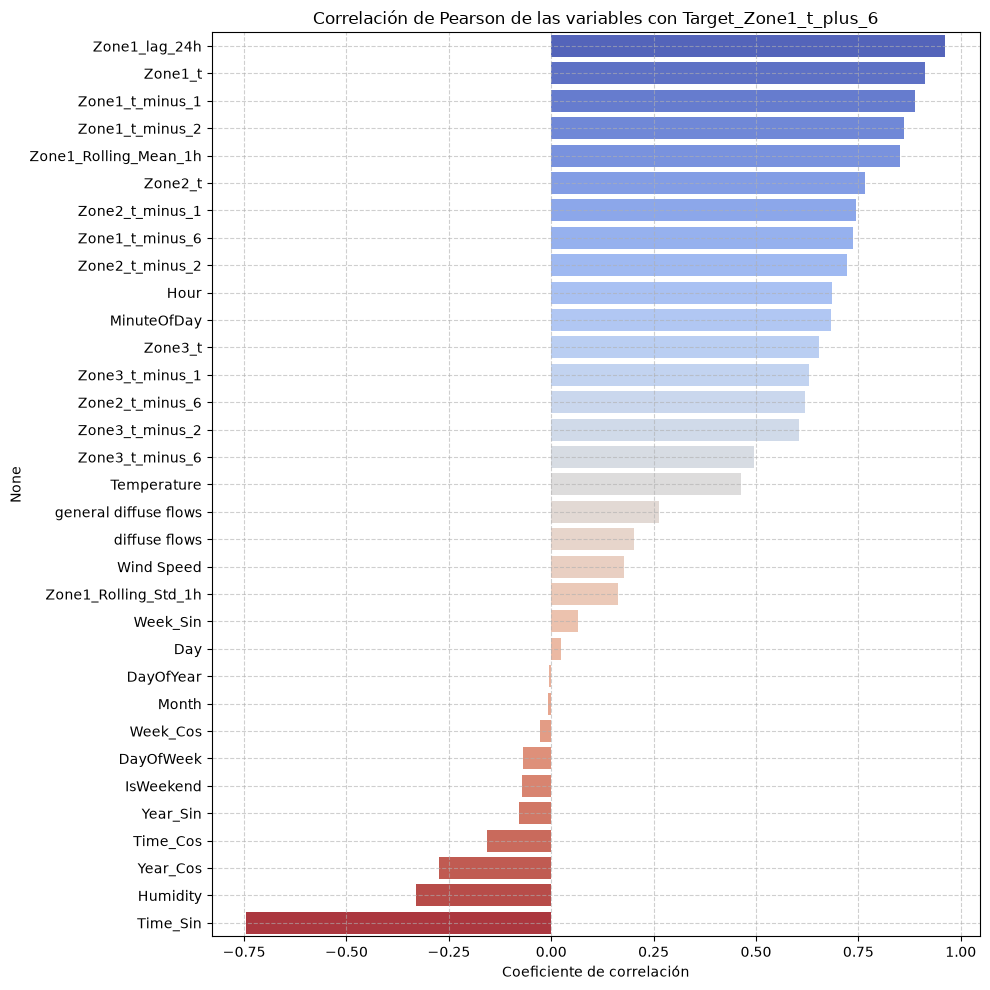


--- Chequeo de Calidad ---
Valores nulos en dataset final: 0
Valores infinitos en dataset final: 0


In [20]:

cols_to_drop = [
    "DateTime",                   # No es predictora
    "Zone 1 Power Consumption",   # Duplicado de Zone1_t
    "Zone 2 Power Consumption",   # Duplicado de Zone2_t
    "Zone 3 Power Consumption",   # Duplicado de Zone3_t
    TARGET,                       # Se separa como y
]
feature_cols = [c for c in df_model.columns if c not in cols_to_drop]

correlations = (
    df_model[feature_cols]
    .apply(lambda col: col.corr(df_model[TARGET]))
    .sort_values(ascending=False)
)

print("--- TOP 10 VARIABLES MÁS CORRELACIONADAS CON EL TARGET (t+6) ---")
print(correlations.head(10))
print("\n--- TOP 5 VARIABLES MENOS CORRELACIONADAS (MÁS CERCANAS A 0) ---")
print(correlations.abs().sort_values().head(5))

plt.figure(figsize=(10, 10))
sns.barplot(x=correlations.values, y=correlations.index,
            hue=correlations.index, palette="coolwarm", legend=False)
plt.title(f"Correlación de Pearson de las variables con {TARGET}")
plt.xlabel("Coeficiente de correlación")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Chequeo de calidad
null_count = df_model[feature_cols + [TARGET]].isnull().sum().sum()
inf_count = np.isinf(df_model[feature_cols]).sum().sum()
print("\n--- Chequeo de Calidad ---")
print(f"Valores nulos en dataset final: {null_count}")
print(f"Valores infinitos en dataset final: {inf_count}")

Con un horizonte de 1 hora, la correlación del consumo actual con el objetivo es menor que con 10 minutos, lo que confirma que el problema ya no se reduce a copiar el valor actual. Las variables de calendario tienen baja correlación lineal, pero se conservan porque su relación con el consumo es cíclica (no lineal), como se vio en los gráficos de picos.

## Partición cronológica (70% entrenamiento, 15% validación, 15% prueba)

Al ser una serie temporal, los datos no se barajan: se entrena con el pasado y se evalúa con el futuro.

In [21]:
X = df_model[feature_cols]
y = df_model[TARGET]

n = len(df_model)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("--- RESUMEN DE LA SELECCIÓN Y PARTICIÓN DE DATOS ---")
print(f"Número de variables predictoras (X): {X.shape[1]}")
print(f"Variables seleccionadas:\n{list(X.columns)}\n")
print(f"Entrenamiento: {len(X_train)} registros ({len(X_train)/n:.1%})")
print(f"Validación:    {len(X_val)} registros ({len(X_val)/n:.1%})")
print(f"Prueba:        {len(X_test)} registros ({len(X_test)/n:.1%})")

fechas = df_model["DateTime"]
print(f"\nRango Train: {fechas.iloc[0]:%Y-%m-%d} a {fechas.iloc[train_end - 1]:%Y-%m-%d}")
print(f"Rango Val:   {fechas.iloc[train_end]:%Y-%m-%d} a {fechas.iloc[val_end - 1]:%Y-%m-%d}")
print(f"Rango Test:  {fechas.iloc[val_end]:%Y-%m-%d} a {fechas.iloc[-1]:%Y-%m-%d}")

--- RESUMEN DE LA SELECCIÓN Y PARTICIÓN DE DATOS ---
Número de variables predictoras (X): 33
Variables seleccionadas:
['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Hour', 'MinuteOfDay', 'Day', 'Month', 'DayOfWeek', 'DayOfYear', 'IsWeekend', 'Time_Sin', 'Time_Cos', 'Week_Sin', 'Week_Cos', 'Year_Sin', 'Year_Cos', 'Zone1_t', 'Zone2_t', 'Zone3_t', 'Zone1_t_minus_1', 'Zone2_t_minus_1', 'Zone3_t_minus_1', 'Zone1_t_minus_2', 'Zone2_t_minus_2', 'Zone3_t_minus_2', 'Zone1_t_minus_6', 'Zone2_t_minus_6', 'Zone3_t_minus_6', 'Zone1_lag_24h', 'Zone1_Rolling_Mean_1h', 'Zone1_Rolling_Std_1h']

Entrenamiento: 36590 registros (70.0%)
Validación:    7841 registros (15.0%)
Prueba:        7841 registros (15.0%)

Rango Train: 2017-01-01 a 2017-09-13
Rango Val:   2017-09-13 a 2017-11-06
Rango Test:  2017-11-06 a 2017-12-30


## Referencias ingenuas

El criterio de éxito compara el modelo con la mejor de tres referencias ingenuas: persistencia (el consumo
actual, `Zone1_t`), ayer a la misma hora (`Zone1_lag_24h`) y la semana pasada a la misma hora (t+6−1008).
Se calculan para las particiones de validación y de prueba.

In [22]:
# Mismo momento de la semana pasada respecto del periodo que se predice (t+6−1008)
serie_z1 = df.set_index("DateTime")["Zone 1 Power Consumption"]
semana_pasada = df_model["DateTime"].map(serie_z1.shift(7 * PERIODOS_DIA - HORIZONTE))

referencias = {
    "Persistencia": X["Zone1_t"],
    "Ayer a la misma hora": X["Zone1_lag_24h"],
    "Semana pasada a la misma hora": semana_pasada,
}
filas = []
for nombre_ref, pred in referencias.items():
    for nombre, tramo in [("Validación", slice(train_end, val_end)), ("Prueba", slice(val_end, None))]:
        mae, rmse, mape = metricas(y.iloc[tramo].values, pred.iloc[tramo].values)
        filas.append({"Referencia": nombre_ref, "Partición": nombre,
                      "MAE (kW)": mae, "RMSE (kW)": rmse, "MAPE (%)": mape})
tabla_referencias = pd.DataFrame(filas).pivot(index="Referencia", columns="Partición")
display(tabla_referencias.round(2))

MAE (kW)            RMSE (kW)             \
Partición                       Prueba Validación    Prueba Validación   
Referencia                                                               
Ayer a la misma hora            983.93    1159.83   1486.60    1643.51   
Persistencia                   1821.29    2073.44   2504.04    2904.34   
Semana pasada a la misma hora   838.10    1443.21   1154.89    1979.99   

                              MAPE (%)             
Partición                       Prueba Validación  
Referencia                                         
Ayer a la misma hora              3.44       3.64  
Persistencia                      6.29       6.24  
Semana pasada a la misma hora     2.94       4.56

## Validación cruzada temporal (*cross-time validation*)

Una sola partición 70/15/15 evalúa el modelo en un único periodo (septiembre–noviembre), por lo que el resultado puede depender de esa época del año. Para medir qué tan estable es el error a lo largo del tiempo se usa **validación cruzada temporal con ventana expansiva** (`TimeSeriesSplit`):

- Se aplica solo sobre **entrenamiento + validación** (85%). El conjunto de prueba no se usa.
- En cada fold se entrena con todo el pasado disponible y se valida con el bloque siguiente; nunca se entrena con datos posteriores a los de validación.
- Se deja un **gap de 6 periodos** (el horizonte) entre entrenamiento y validación: el objetivo de las últimas filas de entrenamiento (t+6) cae dentro del periodo de validación, y sin el gap el modelo vería parte de lo que luego se evalúa.
- Modelo de referencia: `HistGradientBoostingRegressor` (captura relaciones no lineales y no requiere escalar). Se desactiva su *early stopping* porque internamente baraja los datos.
- En cada fold se compara contra las tres referencias ingenuas.

Tiempo: 13.5 s



,Entrenamiento,Validación,Registros train,MAE modelo,MAE persistencia,MAE ayer,MAE semana pasada,MAPE modelo (%),MAE mejor referencia,Mejora vs mejor referencia (%)
Fold,,,,,,,,,,
1,01-Jan a 22-Feb,22-Feb a 14-Apr,7400,812.07,2260.58,1207.40,1079.71,2.67,1079.71,24.79
2,01-Jan a 14-Apr,14-Apr a 05-Jun,14805,896.18,2352.98,1424.70,1583.45,2.85,1424.70,37.10
3,01-Jan a 05-Jun,05-Jun a 26-Jul,22210,1649.87,2283.28,1621.98,2148.15,4.69,1621.98,-1.72
4,01-Jan a 26-Jul,26-Jul a 16-Sep,29615,904.39,2339.33,1373.48,1875.59,2.69,1373.48,34.15
5,01-Jan a 16-Sep,16-Sep a 06-Nov,37020,766.92,2069.32,1179.26,1419.10,2.46,1179.26,34.97



--- Resumen (media ± desviación estándar entre folds) ---
MAE modelo            : 1,006 ± 365 kW
MAE persistencia      : 2,261 ± 114 kW
MAE ayer              : 1,361 ± 180 kW
MAE semana pasada     : 1,621 ± 412 kW
MAE mejor referencia  : 1,336 ± 213 kW
Folds en que el modelo supera a la mejor referencia: 4 de 5


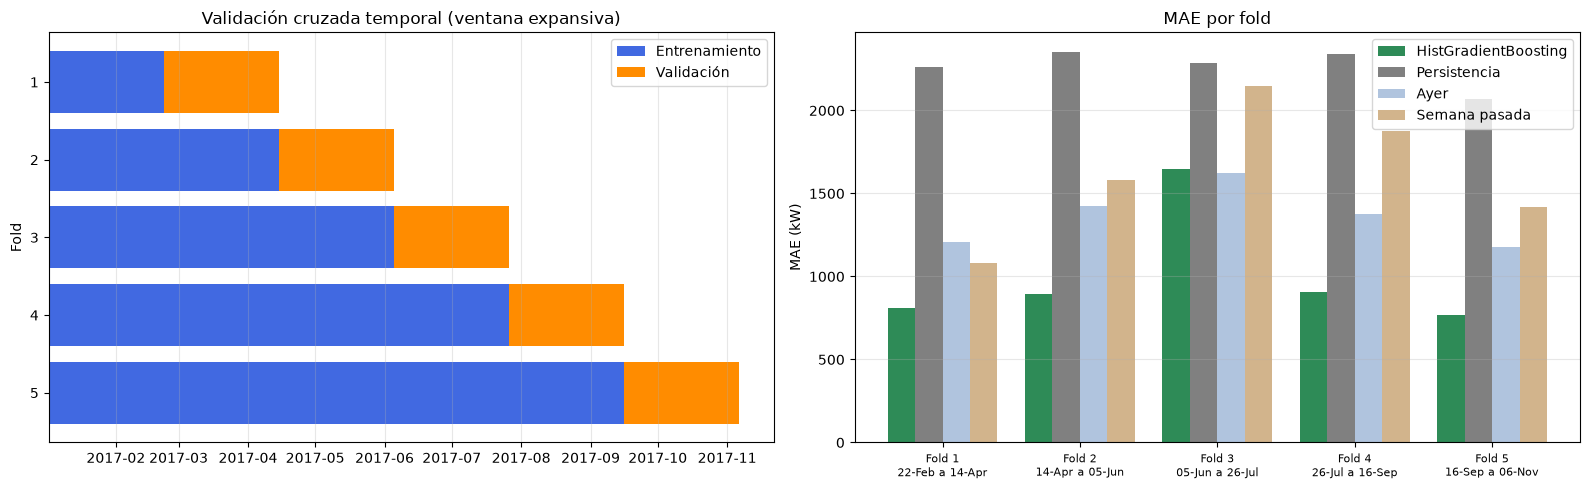

In [23]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import HistGradientBoostingRegressor
import time

# Desarrollo = entrenamiento + validación (85%). La prueba no se toca.
X_dev, y_dev = X.iloc[:val_end], y.iloc[:val_end]
fechas_dev = df_model["DateTime"].iloc[:val_end].reset_index(drop=True)
semana_dev = semana_pasada.iloc[:val_end].reset_index(drop=True)

N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS, gap=HORIZONTE)


def modelo_base():
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, early_stopping=False, random_state=42
    )


inicio = time.time()
resultados_cv = []
for k, (idx_tr, idx_va) in enumerate(tscv.split(X_dev), start=1):
    X_tr, y_tr = X_dev.iloc[idx_tr], y_dev.iloc[idx_tr]
    X_va, y_va = X_dev.iloc[idx_va], y_dev.iloc[idx_va]

    modelo = modelo_base().fit(X_tr, y_tr)
    mae_m, rmse_m, mape_m = metricas(y_va.values, modelo.predict(X_va))
    mae_p, _, _ = metricas(y_va.values, X_va["Zone1_t"].values)
    mae_a, _, _ = metricas(y_va.values, X_va["Zone1_lag_24h"].values)
    mae_s, _, _ = metricas(y_va.values, semana_dev.iloc[idx_va].values)

    resultados_cv.append({
        "Fold": k,
        "Entrenamiento": f"{fechas_dev[idx_tr[0]]:%d-%b} a {fechas_dev[idx_tr[-1]]:%d-%b}",
        "Validación": f"{fechas_dev[idx_va[0]]:%d-%b} a {fechas_dev[idx_va[-1]]:%d-%b}",
        "Registros train": len(idx_tr),
        "MAE modelo": mae_m, "MAE persistencia": mae_p, "MAE ayer": mae_a, "MAE semana pasada": mae_s,
        "MAPE modelo (%)": mape_m,
    })

cv_df = pd.DataFrame(resultados_cv).set_index("Fold")
cv_df["MAE mejor referencia"] = cv_df[["MAE persistencia", "MAE ayer", "MAE semana pasada"]].min(axis=1)
cv_df["Mejora vs mejor referencia (%)"] = (1 - cv_df["MAE modelo"] / cv_df["MAE mejor referencia"]) * 100

print(f"Tiempo: {time.time() - inicio:.1f} s\n")
display(cv_df.round(2))

print("\n--- Resumen (media ± desviación estándar entre folds) ---")
for col in ["MAE modelo", "MAE persistencia", "MAE ayer", "MAE semana pasada", "MAE mejor referencia"]:
    print(f"{col:22s}: {cv_df[col].mean():,.0f} ± {cv_df[col].std():,.0f} kW")
print(f"Folds en que el modelo supera a la mejor referencia: "
      f"{(cv_df['MAE modelo'] < cv_df['MAE mejor referencia']).sum()} de {N_FOLDS}")

# Gráficos: esquema de folds y error por fold
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for k, (idx_tr, idx_va) in enumerate(tscv.split(X_dev), start=1):
    axes[0].barh(k, fechas_dev[idx_tr[-1]] - fechas_dev[idx_tr[0]], left=fechas_dev[idx_tr[0]],
                 color="royalblue", label="Entrenamiento" if k == 1 else None)
    axes[0].barh(k, fechas_dev[idx_va[-1]] - fechas_dev[idx_va[0]], left=fechas_dev[idx_va[0]],
                 color="darkorange", label="Validación" if k == 1 else None)
axes[0].set_yticks(range(1, N_FOLDS + 1))
axes[0].set_ylabel("Fold")
axes[0].invert_yaxis()
axes[0].set_title("Validación cruzada temporal (ventana expansiva)")
axes[0].legend()
axes[0].grid(axis="x", alpha=0.3)

series = {"HistGradientBoosting": ("MAE modelo", "seagreen"), "Persistencia": ("MAE persistencia", "gray"),
          "Ayer": ("MAE ayer", "lightsteelblue"), "Semana pasada": ("MAE semana pasada", "tan")}
ancho = 0.2
pos = np.arange(1, N_FOLDS + 1)
for j, (nombre, (col, color)) in enumerate(series.items()):
    axes[1].bar(pos + (j - 1.5) * ancho, cv_df[col], ancho, label=nombre, color=color)
axes[1].set_xticks(pos)
axes[1].set_xticklabels([f"Fold {k}\n{v}" for k, v in cv_df["Validación"].items()], fontsize=8)
axes[1].set_ylabel("MAE (kW)")
axes[1].set_title("MAE por fold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación de la validación cruzada temporal:**

- El modelo supera a la persistencia en los 5 folds (MAE medio de 1,006 ± 365 kW frente a 2,261 ± 114 kW). Pero
  la persistencia es la referencia más débil, y el criterio de éxito exige superar a la mejor.
- Contra la mejor referencia de cada fold, el modelo gana en 4 de 5, con mejoras de 25 a 37 %. **En el fold 3
  (del 5 de junio al 26 de julio, inicio del verano) pierde:** su MAE (1,650 kW) es levemente peor que el de
  "ayer a la misma hora" (1,622 kW). En ese fold, el modelo solo se entrenó con datos de enero a junio y tiene
  que predecir los meses de mayor consumo, con niveles que no vio. Los modelos de árboles no extrapolan fuera
  del rango de entrenamiento. Cuando el verano ya está en el entrenamiento (fold 4), el modelo vuelve a ganar.
- "Ayer a la misma hora" es la mejor referencia en 4 de los 5 folds, y "semana pasada" en el primero.
- **Implicancia para el modelado:** el verano es el punto débil. Hay que probar formas de que el modelo
  generalice a niveles nuevos, por ejemplo, predecir el cambio respecto del consumo actual en vez del nivel. Y
  hay que evaluar siempre con validación cruzada temporal, no solo con la partición fija.

## Correlaciones no lineales

Es posible que las variables no se correlacionen linealmente con la variable objetivo y aun así aporten información. Por ello, es conveniente realizar un análisis de **información mutua**, que detecta dependencias no lineales e incluso no monótonas (por ejemplo, la hora del día: el consumo sube y baja dentro del mismo ciclo).

- Se calcula **solo con el conjunto de entrenamiento**, para no usar información de validación ni de prueba al analizar las variables.
- Se usa `mutual_info_regression` (estimador por k vecinos más cercanos), indicando cuáles variables son discretas (hora, día, mes, día de la semana, etc.).
- La información mutua vale 0 si la variable y el objetivo son independientes; cuanto mayor, más información comparten (se mide en *nats*, no tiene un máximo fijo).

**Limitación:** es un análisis marginal (evalúa cada variable por separado, sin considerar redundancia entre ellas) y su estimación depende de la muestra y del estimador. Por eso se complementa con la ablación de variables.

Tiempo: 8.3 s



,Información mutua,|Pearson|,Ranking IM,Ranking Pearson,Sube en ranking (IM vs Pearson)
Zone1_lag_24h,1.405,0.957,1,1,0
Zone1_t,1.079,0.910,2,2,0
Zone1_t_minus_1,0.965,0.884,3,3,0
MinuteOfDay,0.886,0.697,4,14,10
Zone1_t_minus_2,0.867,0.855,5,4,-1
Zone1_Rolling_Mean_1h,0.839,0.846,6,6,0
Hour,0.834,0.697,7,13,6
Zone2_t,0.751,0.851,8,5,-3
Zone2_t_minus_1,0.690,0.830,9,7,-2
Zone2_t_minus_2,0.640,0.807,10,8,-2



--- Variables con dependencia principalmente no lineal ---
(suben 5 o más puestos en el ranking al pasar de Pearson a información mutua)
             Información mutua  |Pearson|  Ranking IM  Ranking Pearson
MinuteOfDay              0.886      0.697           4               14
Hour                     0.834      0.697           7               13
Time_Cos                 0.498      0.123          16               28

--- Variables con información mutua cercana a 0 (< 0.05) ---
IsWeekend    0.017
Week_Cos     0.018
Week_Sin     0.033
DayOfWeek    0.033
dtype: float64


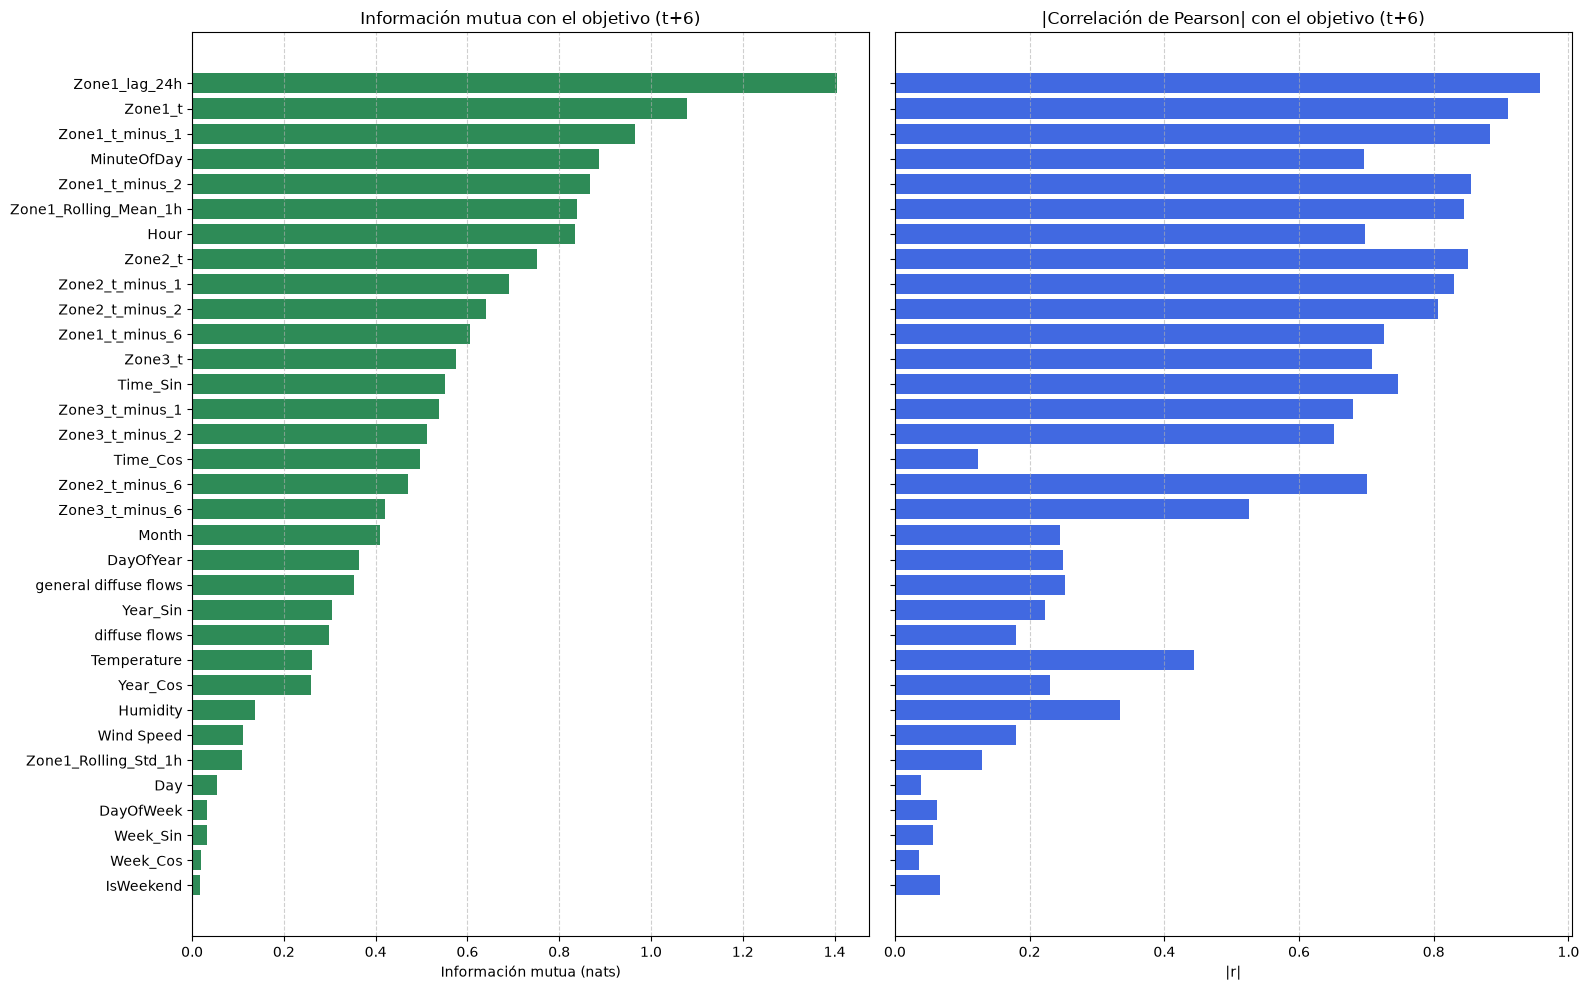

In [24]:
from sklearn.feature_selection import mutual_info_regression

discretas = ["Hour", "MinuteOfDay", "Day", "Month", "DayOfWeek", "DayOfYear", "IsWeekend"]
mascara_discretas = X_train.columns.isin(discretas)

inicio = time.time()
mi = pd.Series(
    mutual_info_regression(X_train, y_train, discrete_features=mascara_discretas,
                           n_neighbors=3, random_state=42),
    index=X_train.columns,
)
print(f"Tiempo: {time.time() - inicio:.1f} s\n")

# Comparación con la correlación de Pearson (también solo en entrenamiento)
pearson_abs = X_train.corrwith(y_train).abs()
comparacion = pd.DataFrame({
    "Información mutua": mi,
    "|Pearson|": pearson_abs,
    "Ranking IM": mi.rank(ascending=False).astype(int),
    "Ranking Pearson": pearson_abs.rank(ascending=False).astype(int),
}).sort_values("Información mutua", ascending=False)
comparacion["Sube en ranking (IM vs Pearson)"] = comparacion["Ranking Pearson"] - comparacion["Ranking IM"]

display(comparacion.round(3))

print("\n--- Variables con dependencia principalmente no lineal ---")
print("(suben 5 o más puestos en el ranking al pasar de Pearson a información mutua)")
no_lineales = comparacion[comparacion["Sube en ranking (IM vs Pearson)"] >= 5]
print(no_lineales[["Información mutua", "|Pearson|", "Ranking IM", "Ranking Pearson"]].round(3))

print("\n--- Variables con información mutua cercana a 0 (< 0.05) ---")
print(mi[mi < 0.05].sort_values().round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)
orden = comparacion.index
axes[0].barh(orden, comparacion["Información mutua"], color="seagreen")
axes[0].set_title("Información mutua con el objetivo (t+6)")
axes[0].set_xlabel("Información mutua (nats)")
axes[1].barh(orden, comparacion["|Pearson|"], color="royalblue")
axes[1].set_title("|Correlación de Pearson| con el objetivo (t+6)")
axes[1].set_xlabel("|r|")
for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.6)
axes[0].invert_yaxis()  # el eje Y es compartido: se invierte una sola vez
plt.tight_layout()
plt.show()

**Interpretación de la información mutua:**
- Los rezagos de la Zona 1 (rezago diario t−138, t y t−1) concentran la mayor información sobre el objetivo, igual que con Pearson.
- Las variables de **hora del día** son las que más suben en el ranking frente a Pearson: `Time_Cos` pasa del puesto 28 al 16 (|r| = 0.12, pero IM = 0.50), `MinuteOfDay` del 14 al 4 y `Hour` del 13 al 7. Su relación con el consumo es cíclica (mínimo en la madrugada y máximo en la noche) y la correlación lineal no la capta. Esto respalda conservar el calendario diario aunque su correlación lineal sea baja.
- `Temperature` y `Humidity` bajan en el ranking (del puesto 18 al 24 y del 19 al 26): tienen relación lineal con el consumo, pero comparten menos información con el objetivo que los rezagos y la hora del día.
- Las variables **semanales** (`IsWeekend`, `DayOfWeek`, `Week_Sin`, `Week_Cos`) tienen información mutua cercana a 0: por sí solas casi no dicen nada del consumo en t+6. Como el análisis es marginal, esto no significa que no aporten dentro del modelo; eso se evalúa con la ablación.

## Ablación de variables

La información mutua mide cada variable por separado. La **ablación** mide cuánto aporta cada **grupo de variables dentro del modelo**, considerando que muchas son redundantes entre sí (por ejemplo, `Hour`, `MinuteOfDay`, `Time_Sin` y `Time_Cos` describen el mismo ciclo diario).

Procedimiento (*leave-one-group-out*):
1. Se entrena el modelo con todas las variables y se mide el MAE en cada fold de la validación cruzada temporal.
2. Se repite quitando un grupo a la vez, con los mismos folds.
3. **ΔMAE = MAE sin el grupo − MAE con todas las variables.** Si es positivo, quitar el grupo empeora el modelo (el grupo aporta). Si es cercano a 0 o negativo, el grupo es redundante o introduce ruido.

Los grupos de calendario se separan por ciclo (diario, semanal, anual) para verificar la limitación señalada antes: con un solo año de datos, el patrón anual no se puede aprender completamente.

Clima                                         ΔMAE =    +13.9 kW


Calendario diario                             ΔMAE =    +23.6 kW


Calendario semanal                            ΔMAE =    +92.4 kW


Calendario anual (día, mes, día del año)      ΔMAE =    -83.9 kW


Zona 1 reciente (t, t−1, t−2, t−6)            ΔMAE =    +89.7 kW


Zona 1 rezago diario (t−138)                  ΔMAE =   +174.6 kW


Zona 1 estadísticas móviles (1 h)             ΔMAE =     +7.4 kW


Zonas 2 y 3 (rezagos)                         ΔMAE =    +20.0 kW

Tiempo: 83.4 s
MAE con todas las variables: 1,006 ± 365 kW



,N° variables,ΔMAE medio (kW),ΔMAE desv. est. (kW),ΔMAE (%),Folds en que empeora
Grupo,,,,,
Zona 1 rezago diario (t−138),1,174.55,201.88,17.35,3 de 5
Calendario semanal,4,92.36,57.54,9.18,5 de 5
"Zona 1 reciente (t, t−1, t−2, t−6)",4,89.70,34.18,8.92,5 de 5
Calendario diario,4,23.55,28.27,2.34,4 de 5
Zonas 2 y 3 (rezagos),8,20.03,76.97,1.99,3 de 5
Clima,5,13.94,27.07,1.39,4 de 5
Zona 1 estadísticas móviles (1 h),2,7.41,15.70,0.74,3 de 5
"Calendario anual (día, mes, día del año)",5,-83.87,102.45,-8.34,1 de 5


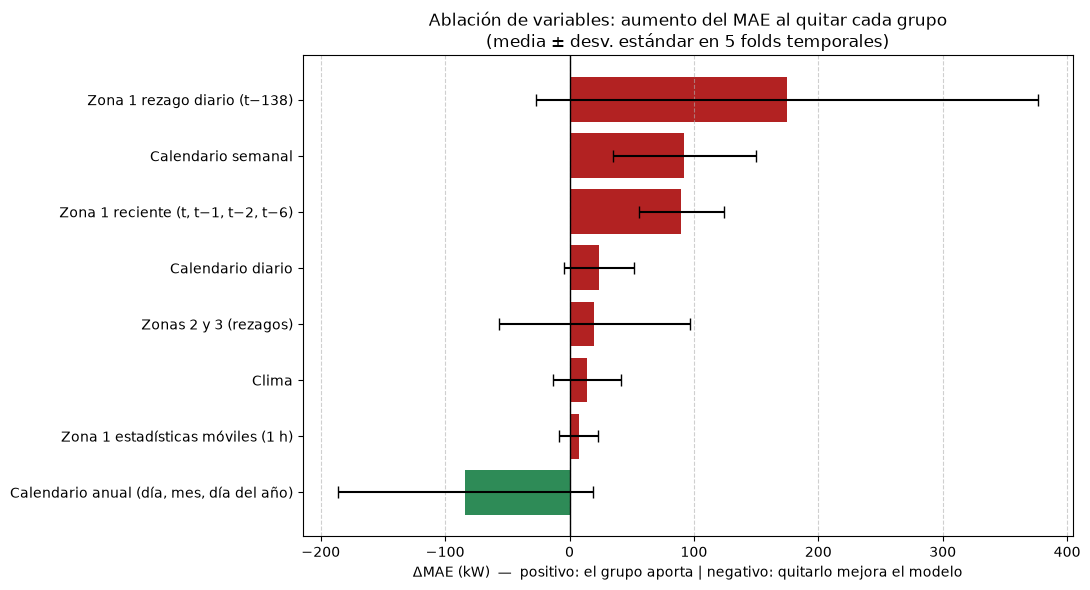

In [25]:
grupos = {
    "Clima": ["Temperature", "Humidity", "Wind Speed", "general diffuse flows", "diffuse flows"],
    "Calendario diario": ["Hour", "MinuteOfDay", "Time_Sin", "Time_Cos"],
    "Calendario semanal": ["DayOfWeek", "IsWeekend", "Week_Sin", "Week_Cos"],
    "Calendario anual (día, mes, día del año)": ["Day", "Month", "DayOfYear", "Year_Sin", "Year_Cos"],
    "Zona 1 reciente (t, t−1, t−2, t−6)": ["Zone1_t", "Zone1_t_minus_1", "Zone1_t_minus_2", "Zone1_t_minus_6"],
    "Zona 1 rezago diario (t−138)": ["Zone1_lag_24h"],
    "Zona 1 estadísticas móviles (1 h)": ["Zone1_Rolling_Mean_1h", "Zone1_Rolling_Std_1h"],
    "Zonas 2 y 3 (rezagos)": [c for c in feature_cols if c.startswith(("Zone2", "Zone3"))],
}
# Cada variable predictora pertenece a exactamente un grupo
assert sorted(sum(grupos.values(), [])) == sorted(feature_cols)


def mae_por_fold(columnas):
    maes = []
    for idx_tr, idx_va in tscv.split(X_dev):
        modelo = modelo_base().fit(X_dev.iloc[idx_tr][columnas], y_dev.iloc[idx_tr])
        pred = modelo.predict(X_dev.iloc[idx_va][columnas])
        maes.append(metricas(y_dev.iloc[idx_va].values, pred)[0])
    return np.array(maes)


inicio = time.time()
mae_todas = mae_por_fold(feature_cols)

filas = []
for nombre, cols_grupo in grupos.items():
    restantes = [c for c in feature_cols if c not in cols_grupo]
    delta = mae_por_fold(restantes) - mae_todas
    filas.append({
        "Grupo": nombre,
        "N° variables": len(cols_grupo),
        "ΔMAE medio (kW)": delta.mean(),
        "ΔMAE desv. est. (kW)": delta.std(ddof=1),
        "ΔMAE (%)": delta.mean() / mae_todas.mean() * 100,
        "Folds en que empeora": f"{(delta > 0).sum()} de {N_FOLDS}",
    })
    print(f"{nombre:45s} ΔMAE = {delta.mean():+8.1f} kW")

ablacion = pd.DataFrame(filas).set_index("Grupo").sort_values("ΔMAE medio (kW)", ascending=False)
print(f"\nTiempo: {time.time() - inicio:.1f} s")
print(f"MAE con todas las variables: {mae_todas.mean():,.0f} ± {mae_todas.std(ddof=1):,.0f} kW\n")
display(ablacion.round(2))

colores = ["firebrick" if v > 0 else "seagreen" for v in ablacion["ΔMAE medio (kW)"]]
plt.figure(figsize=(11, 6))
plt.barh(ablacion.index, ablacion["ΔMAE medio (kW)"], xerr=ablacion["ΔMAE desv. est. (kW)"],
         color=colores, capsize=4)
plt.axvline(0, color="black", linewidth=1)
plt.gca().invert_yaxis()
plt.title("Ablación de variables: aumento del MAE al quitar cada grupo\n(media ± desv. estándar en 5 folds temporales)")
plt.xlabel("ΔMAE (kW)  —  positivo: el grupo aporta | negativo: quitarlo mejora el modelo")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

**Interpretación de la ablación:**

- **Rezago diario de la Zona 1:** es el grupo más importante (+175 kW, +17.4 % de MAE al quitarlo), aunque
  con mucha variación entre folds (±202 kW): empeora el modelo en 3 de 5.
- **Rezagos recientes de la Zona 1:** +90 kW. Empeora el modelo en los 5 folds: es de los aportes más
  consistentes.
- **Calendario semanal:** +92 kW en los 5 folds, a pesar de que su información mutua era casi 0. Es el caso que
  justifica combinar ambos análisis: por sí solo no informa sobre el consumo, pero sí junto con los rezagos.
  Una explicación posible es que el rezago de 24 h de un lunes corresponde a un domingo, y el modelo necesita
  el día de la semana para corregir esa diferencia.
- **Calendario diario:** +24 kW. Aporta, aunque es en parte redundante con los rezagos, que ya contienen el
  ciclo diario.
- **Zonas 2 y 3, estadísticas móviles y clima:** aportes pequeños (de +7 a +20 kW), con una desviación entre
  folds mayor que la media, así que su efecto no se distingue de 0.
- **Calendario anual:** quitarlo **mejora** el MAE en 84 kW (−8.3 %) y solo ayuda en 1 de 5 folds. Esto
  confirma la limitación señalada antes: con un solo año de datos, `Month`, `DayOfYear`, `Day`, `Year_Sin` y
  `Year_Cos` funcionan como identificadores de cada época. El modelo aprende el nivel de cada periodo y no
  generaliza a fechas que no vio.

**Conclusión:** la información mutua y la ablación coinciden en que los rezagos de la Zona 1 son las variables
clave, y discrepan en el calendario semanal, que solo aporta en combinación con otras variables. Para la fase
de modelado se propone evaluar la exclusión del calendario anual y validar con la validación cruzada temporal,
no solo con la partición fija.

## Revisión de data leakage

- **Variables disponibles en t:** el clima observado, el calendario, los rezagos (t, t−1, t−2, t−6, t−138) y las estadísticas móviles (t−5 a t) se conocen al momento de predecir. Ninguna usa información de t+1 en adelante.
- **El objetivo no se filtra como predictora:** se eliminaron Zone 1/2/3 Power Consumption porque duplican Zone1_t, Zone2_t y Zone3_t, y Target_Zone1_t_plus_6 se separa como y.
- **Partición cronológica:** entrenamiento, validación y prueba no se mezclan ni se barajan, así el modelo nunca ve datos del futuro al entrenar.
- **Filas eliminadas:** solo las que no tienen historial suficiente o no tienen objetivo; no se imputa nada que pueda traer información futura.

## Verificación final de la estructura y calidad del dataset

In [26]:
print("--- Estructura del dataset final ---")
df_model.info()

print(f"\nDimensiones finales: {df_model.shape}")
print(f"Valores nulos: {df_model.isnull().sum().sum()}")
print(f"Filas duplicadas: {df_model.duplicated().sum()}")
print(f"Fechas duplicadas: {df_model['DateTime'].duplicated().sum()}")
print(f"Orden cronológico correcto: {df_model['DateTime'].is_monotonic_increasing}")

display(df_model.head())

--- Estructura del dataset final ---
<class 'pandas.DataFrame'>
RangeIndex: 52272 entries, 0 to 52271
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DateTime                  52272 non-null  datetime64[us]
 1   Temperature               52272 non-null  float64       
 2   Humidity                  52272 non-null  float64       
 3   Wind Speed                52272 non-null  float64       
 4   general diffuse flows     52272 non-null  float64       
 5   diffuse flows             52272 non-null  float64       
 6   Zone 1 Power Consumption  52272 non-null  float64       
 7   Zone 2 Power Consumption  52272 non-null  float64       
 8   Zone 3 Power Consumption  52272 non-null  float64       
 9   Hour                      52272 non-null  int32         
 10  MinuteOfDay               52272 non-null  int32         
 11  Day                       52272 non-null  int32       

,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption,Hour,...,Zone3_t_minus_1,Zone1_t_minus_2,Zone2_t_minus_2,Zone3_t_minus_2,Zone1_t_minus_6,Zone2_t_minus_6,Zone3_t_minus_6,Zone1_lag_24h,Zone1_Rolling_Mean_1h,Zone1_Rolling_Std_1h
0,2017-01-01 23:00:00,12.11,69.94,0.074,0.088,0.082,32117.46835,21253.49544,20686.26506,23,...,21264.57831,33678.98734,22489.96960,21813.97590,36953.92405,24000.00000,23976.86747,34055.69620,34166.075947,1544.173177
1,2017-01-01 23:10:00,12.07,70.70,0.076,0.033,0.078,31357.97468,20768.38906,20397.10843,23,...,20686.26506,33077.46835,21760.48632,21264.57831,36394.93671,23872.34043,23415.90361,29814.68354,33326.582275,1456.809437
2,2017-01-01 23:20:00,11.99,70.80,0.075,0.055,0.134,30701.77215,20337.99392,19905.54217,23,...,20397.10843,32117.46835,21253.49544,20686.26506,35289.11392,23306.99088,22698.79518,29128.10127,32562.025313,1424.238907
3,2017-01-01 23:30:00,11.32,74.70,0.075,0.070,0.100,29681.01266,19823.70821,19252.04819,23,...,19905.54217,31357.97468,20768.38906,20397.10843,34438.48101,22975.07599,22322.89157,28228.86076,31769.113922,1493.263500
4,2017-01-01 23:40:00,11.37,74.80,0.074,0.084,0.082,28830.37975,19488.14590,18847.22892,23,...,19252.04819,30701.77215,20337.99392,19905.54217,33678.98734,22489.96960,21813.97590,27335.69620,30961.012657,1563.301349
